In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Environment ready!")

Environment ready!


In [2]:
DATA_PATH = "../data/Practise dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (990, 16)


,Product_ID,Product_Name,Catagory,Supplier_ID,Supplier_Name,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Date_Received,Last_Order_Date,Expiration_Date,Warehouse_Location,Sales_Volume,Inventory_Turnover_Rate,Status
0,29-205-1132,Sushi Rice,Grains & Pulses,38-037-1699,Jaxnation,22,72,70,$4.50,8/16/2024,6/29/2024,9/19/2024,48 Del Sol Trail,32,19,Discontinued
1,40-681-9981,Arabica Coffee,Beverages,54-470-2479,Feedmix,45,77,2,$20.00,11/1/2024,5/29/2024,5/8/2024,36 3rd Place,85,1,Discontinued
2,06-955-3428,Black Rice,Grains & Pulses,54-031-2945,Vinder,30,38,83,$6.00,8/3/2024,6/10/2024,9/22/2024,3296 Walton Court,31,34,Backordered
3,71-594-6552,Long Grain Rice,Grains & Pulses,63-492-7603,Brightbean,12,59,62,$1.50,12/8/2024,2/19/2025,4/17/2024,3 Westerfield Crossing,95,99,Active
4,57-437-1828,Plum,Fruits & Vegetables,54-226-4308,Topicstorm,37,30,74,$4.00,7/3/2024,10/11/2024,10/5/2024,15068 Scoville Court,62,25,Backordered


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Product_ID               990 non-null    object
 1   Product_Name             990 non-null    object
 2   Catagory                 989 non-null    object
 3   Supplier_ID              990 non-null    object
 4   Supplier_Name            990 non-null    object
 5   Stock_Quantity           990 non-null    int64 
 6   Reorder_Level            990 non-null    int64 
 7   Reorder_Quantity         990 non-null    int64 
 8   Unit_Price               990 non-null    object
 9   Date_Received            990 non-null    object
 10  Last_Order_Date          990 non-null    object
 11  Expiration_Date          990 non-null    object
 12  Warehouse_Location       990 non-null    object
 13  Sales_Volume             990 non-null    int64 
 14  Inventory_Turnover_Rate  990 non-null    i

In [4]:
df.isnull().sum()

Product_ID                 0
Product_Name               0
Catagory                   1
Supplier_ID                0
Supplier_Name              0
Stock_Quantity             0
Reorder_Level              0
Reorder_Quantity           0
Unit_Price                 0
Date_Received              0
Last_Order_Date            0
Expiration_Date            0
Warehouse_Location         0
Sales_Volume               0
Inventory_Turnover_Rate    0
Status                     0
dtype: int64

In [5]:
df.describe()

,Stock_Quantity,Reorder_Level,Reorder_Quantity,Sales_Volume,Inventory_Turnover_Rate
count,990.000000,990.000000,990.000000,990.000000,990.000000
mean,55.609091,51.215152,51.913131,58.925253,50.150505
std,26.300775,29.095241,29.521059,23.002318,28.798954
min,10.000000,1.000000,1.000000,20.000000,1.000000
25%,33.000000,25.250000,25.000000,39.000000,25.000000
50%,56.000000,53.000000,54.000000,58.000000,50.000000
75%,79.000000,77.000000,77.000000,78.000000,74.750000
max,100.000000,100.000000,100.000000,100.000000,100.000000


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumns:")
for col in df.columns:
    print("-", col)

Rows: 990
Columns: 16

Columns:
- Product_ID
- Product_Name
- Catagory
- Supplier_ID
- Supplier_Name
- Stock_Quantity
- Reorder_Level
- Reorder_Quantity
- Unit_Price
- Date_Received
- Last_Order_Date
- Expiration_Date
- Warehouse_Location
- Sales_Volume
- Inventory_Turnover_Rate
- Status


In [7]:
missing = df.isnull().sum()
print("Missing values:")
print(missing[missing > 0])

Missing values:
Catagory    1
dtype: int64


In [8]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [9]:
print("Unique Product IDs:", df["Product_ID"].nunique())
print("Unique Product Names:", df["Product_Name"].nunique())
print("Unique Categories:", df["Catagory"].nunique())
print("Unique Suppliers:", df["Supplier_ID"].nunique())

Unique Product IDs: 990
Unique Product Names: 121
Unique Categories: 7
Unique Suppliers: 990


In [10]:
print(df["Sales_Volume"].describe())

count    990.000000
mean      58.925253
std       23.002318
min       20.000000
25%       39.000000
50%       58.000000
75%       78.000000
max      100.000000
Name: Sales_Volume, dtype: float64


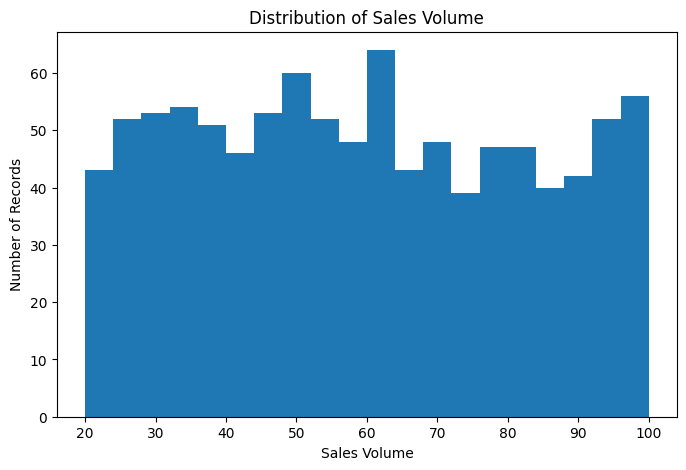

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df["Sales_Volume"], bins=20)
plt.xlabel("Sales Volume")
plt.ylabel("Number of Records")
plt.title("Distribution of Sales Volume")
plt.show()

In [12]:
product_sales = (
    df.groupby("Product_Name")["Sales_Volume"]
      .agg(["count", "mean", "sum"])
      .sort_values("sum", ascending=False)
)

product_sales.head(10)

,count,mean,sum
Product_Name,,,
Bread Flour,19,52.736842,1002
Pomegranate,15,64.800000,972
Cauliflower,15,60.733333,911
Haddock,14,63.714286,892
Arabica Coffee,16,54.625000,874
Jasmine Rice,13,61.076923,794
Egg (Goose),13,59.230769,770
Grapes,14,54.071429,757
Black Rice,12,61.416667,737


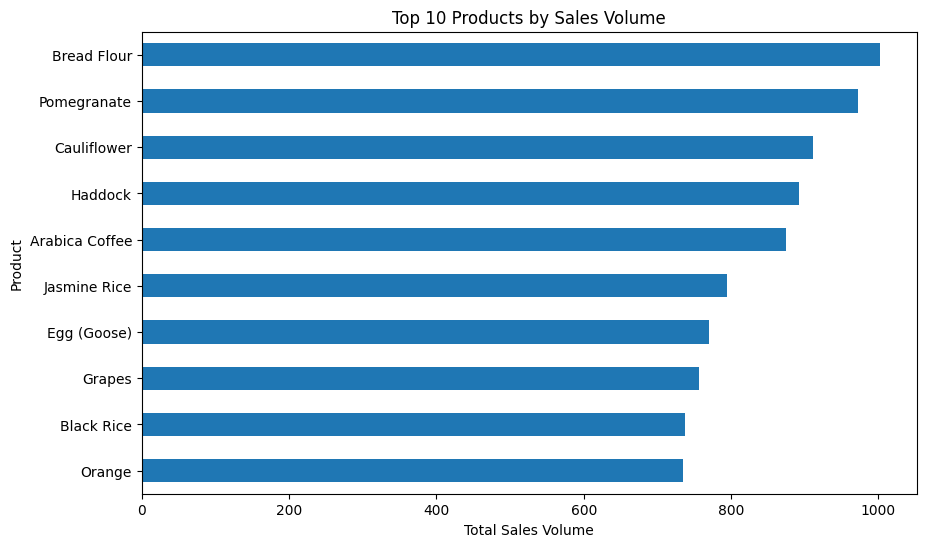

In [13]:
plt.figure(figsize=(10, 6))
product_sales.head(10)["sum"].sort_values().plot(kind="barh")
plt.xlabel("Total Sales Volume")
plt.ylabel("Product")
plt.title("Top 10 Products by Sales Volume")
plt.show()

In [14]:
category_sales = (
    df.groupby("Catagory")["Sales_Volume"]
      .agg(["count", "mean", "sum"])
      .sort_values("sum", ascending=False)
)

category_sales

,count,mean,sum
Catagory,,,
Fruits & Vegetables,331,58.492447,19361
Dairy,180,59.844444,10772
Grains & Pulses,162,54.851852,8886
Seafood,90,61.977778,5578
Oils & Fats,77,59.818182,4606
Bakery,74,61.675676,4564
Beverages,75,60.440000,4533


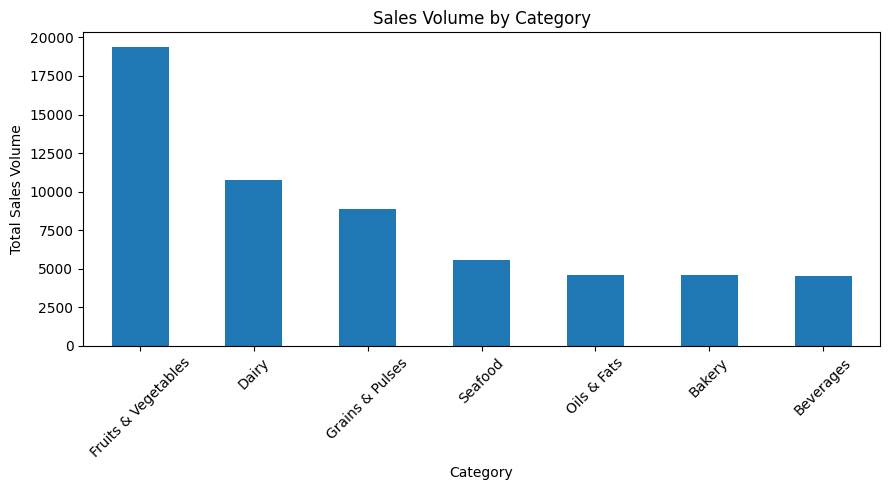

In [15]:
plt.figure(figsize=(9, 5))
category_sales["sum"].plot(kind="bar")
plt.xlabel("Category")
plt.ylabel("Total Sales Volume")
plt.title("Sales Volume by Category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
df["Last_Order_Date"] = pd.to_datetime(df["Last_Order_Date"])
df["Date_Received"] = pd.to_datetime(df["Date_Received"])
df["Expiration_Date"] = pd.to_datetime(df["Expiration_Date"])
print("Last Order Date:")
print("Start:", df["Last_Order_Date"].min())
print("End:", df["Last_Order_Date"].max())
print("Unique dates:", df["Last_Order_Date"].nunique())

Last Order Date:
Start: 2024-02-25 00:00:00
End: 2025-02-24 00:00:00
Unique dates: 332


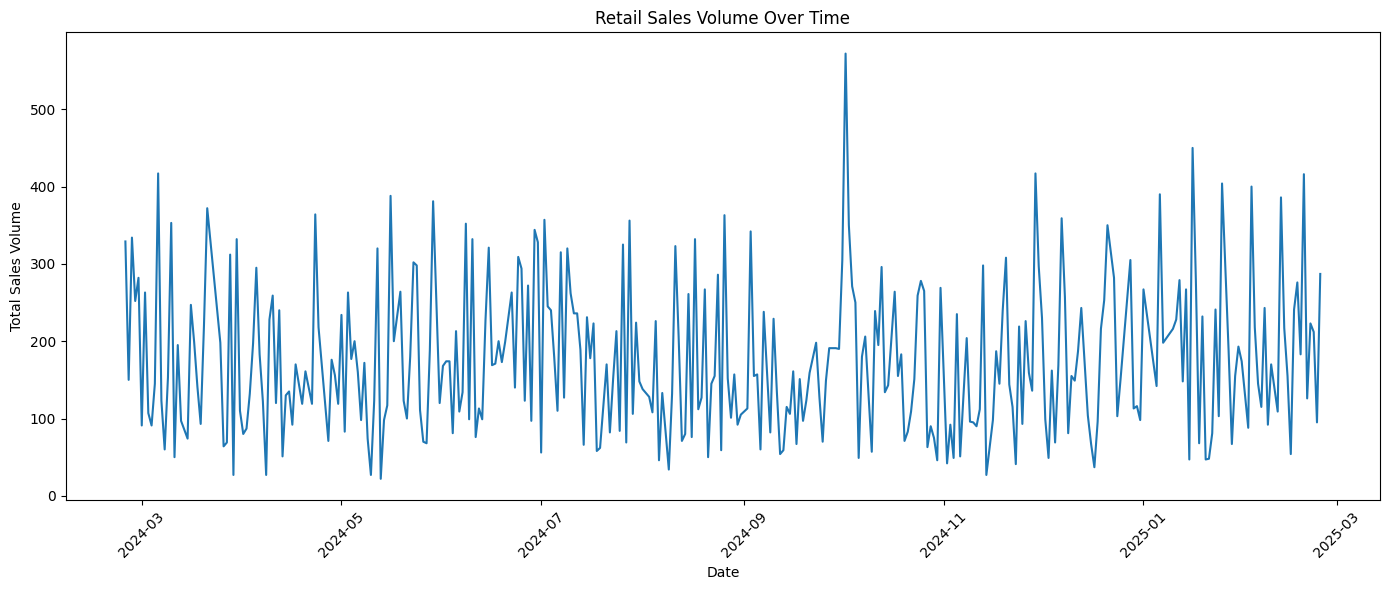

In [17]:
daily_sales = (
    df.groupby("Last_Order_Date")["Sales_Volume"]
      .sum()
      .sort_index()
)
plt.figure(figsize=(14, 6))
plt.plot(daily_sales.index, daily_sales.values)
plt.xlabel("Date")
plt.ylabel("Total Sales Volume")
plt.title("Retail Sales Volume Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
monthly_sales = (
    df.set_index("Last_Order_Date")
      .resample("ME")["Sales_Volume"]
      .sum()
)
print(monthly_sales)

Last_Order_Date
2024-02-29    1347
2024-03-31    4603
2024-04-30    4051
2024-05-31    4961
2024-06-30    5754
2024-07-31    5619
2024-08-31    4465
2024-09-30    3720
2024-10-31    5608
2024-11-30    4345
2024-12-31    4500
2025-01-31    4912
2025-02-28    4451
Freq: ME, Name: Sales_Volume, dtype: int64


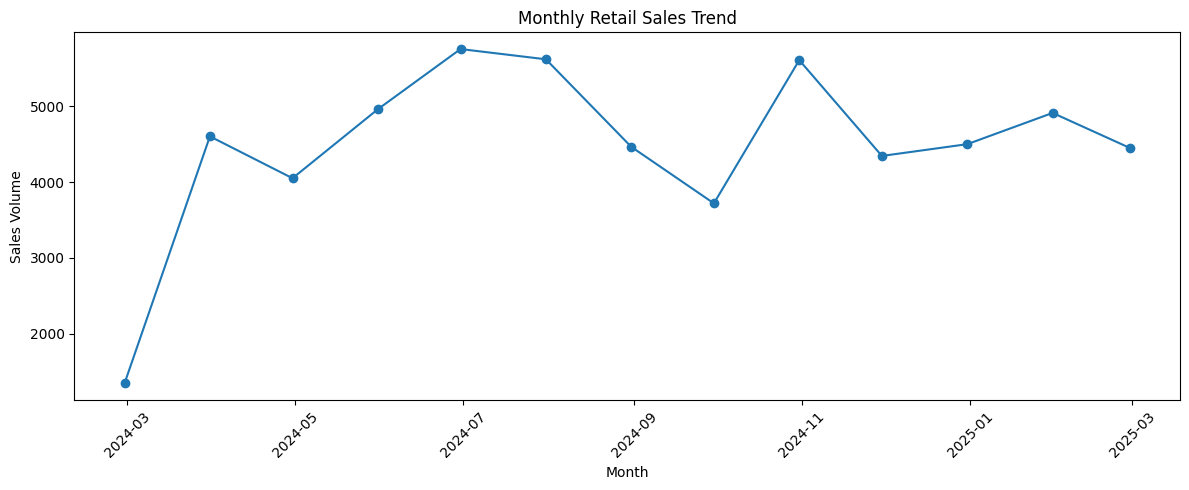

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Sales Volume")
plt.title("Monthly Retail Sales Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
df["Week"] = df["Last_Order_Date"].dt.to_period("W").apply(
    lambda x: x.start_time
)
weekly_sales = (
    df.groupby("Week")["Sales_Volume"]
      .sum()
      .sort_index()
)
print("Number of weeks:", len(weekly_sales))
print(weekly_sales.head(10))

Number of weeks: 54
Week
2024-02-19     329
2024-02-26    1479
2024-03-04    1342
2024-03-11     862
2024-03-18     826
2024-03-25    1112
2024-04-01    1096
2024-04-08    1055
2024-04-15     677
2024-04-22     948
Name: Sales_Volume, dtype: int64


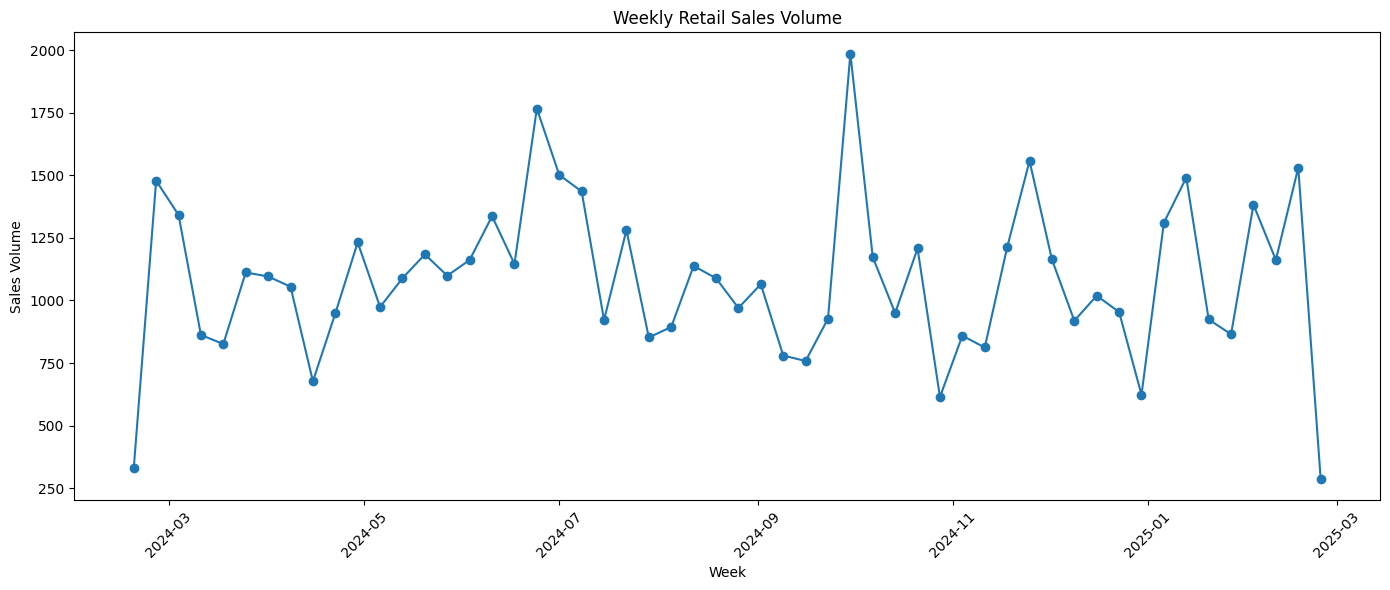

In [21]:
plt.figure(figsize=(14, 6))
plt.plot(
    weekly_sales.index,
    weekly_sales.values,
    marker="o"
)
plt.xlabel("Week")
plt.ylabel("Sales Volume")
plt.title("Weekly Retail Sales Volume")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
print("Weekly Sales Statistics")
print(weekly_sales.describe())

Weekly Sales Statistics
count      54.000000
mean     1080.296296
std       316.326296
min       287.000000
25%       900.250000
50%      1089.000000
75%      1227.000000
max      1987.000000
Name: Sales_Volume, dtype: float64


In [23]:
print("Minimum weekly demand:", weekly_sales.min())
print("Maximum weekly demand:", weekly_sales.max())
print("Average weekly demand:", weekly_sales.mean())

Minimum weekly demand: 287
Maximum weekly demand: 1987
Average weekly demand: 1080.2962962962963


In [24]:
product_weekly = (
    df.groupby(["Product_Name", "Week"])["Sales_Volume"]
      .sum()
      .reset_index()
)
print("Product-week records:", len(product_weekly))
print("Products:", product_weekly["Product_Name"].nunique())

Product-week records: 904
Products: 121


In [25]:
product_counts = (
    product_weekly.groupby("Product_Name")
    .size()
    .sort_values(ascending=False)
)

print(product_counts.head(20))

Product_Name
Bread Flour        16
Arabica Coffee     15
Cauliflower        14
Haddock            14
Grapes             13
Pomegranate        13
Egg (Goose)        12
Onion              12
Bell Pepper        11
White Sugar        11
Jasmine Rice       11
Sourdough Bread    10
Sesame Oil         10
Cucumber           10
Eggplant           10
Anchovies          10
Black Rice         10
Orange             10
Peanut Oil          9
Egg (Turkey)        9
dtype: int64


In [26]:
print("\nProduct observation statistics:")
print(product_counts.describe())


Product observation statistics:
count    121.000000
mean       7.471074
std        2.463312
min        3.000000
25%        6.000000
50%        7.000000
75%        9.000000
max       16.000000
dtype: float64


In [27]:
bread = (
    product_weekly[
        product_weekly["Product_Name"] == "Bread Flour"
    ]
    .sort_values("Week")
)

print(bread)

    Product_Name       Week  Sales_Volume
124  Bread Flour 2024-02-26            32
125  Bread Flour 2024-03-04            66
126  Bread Flour 2024-03-25            81
127  Bread Flour 2024-04-15            55
128  Bread Flour 2024-08-12            80
129  Bread Flour 2024-08-26            31
130  Bread Flour 2024-09-23            58
131  Bread Flour 2024-09-30            35
132  Bread Flour 2024-10-21            27
133  Bread Flour 2024-11-04           149
134  Bread Flour 2024-11-18            78
135  Bread Flour 2024-12-02            83
136  Bread Flour 2024-12-09            49
137  Bread Flour 2024-12-16            33
138  Bread Flour 2024-12-23            92
139  Bread Flour 2025-02-17            53


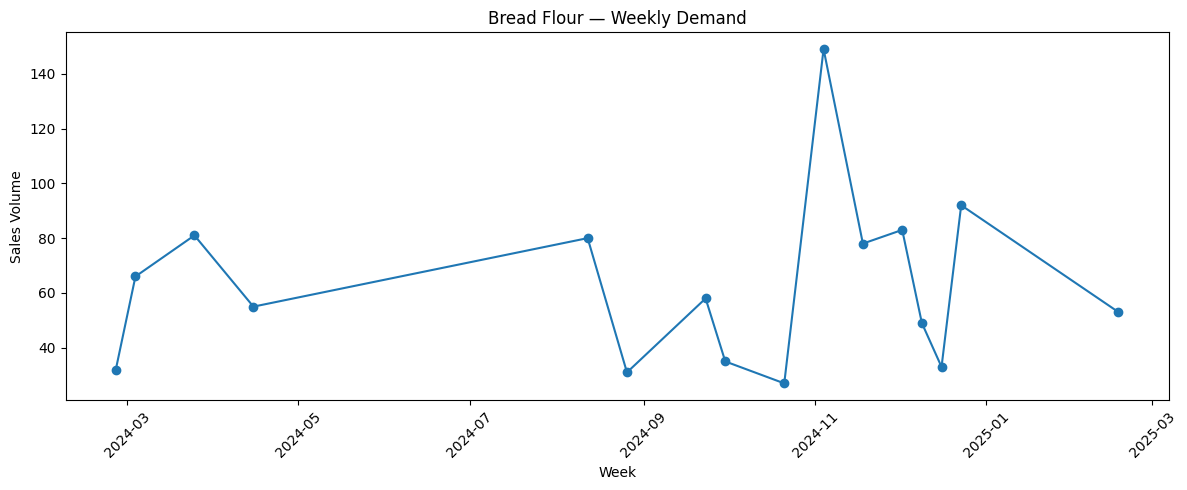

In [31]:
plt.figure(figsize=(12, 5))

plt.plot(
    bread["Week"],
    bread["Sales_Volume"],
    marker="o"
)

plt.xlabel("Week")
plt.ylabel("Sales Volume")
plt.title("Bread Flour — Weekly Demand")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
weekly_df = (
    df.groupby(["Product_Name", "Week"])
      .agg({
          "Sales_Volume": "sum",
          "Stock_Quantity": "mean",
          "Reorder_Level": "mean",
          "Reorder_Quantity": "mean",
          "Unit_Price": "first",
          "Catagory": "first"
      })
      .reset_index()
)

weekly_df = weekly_df.sort_values(
    ["Product_Name", "Week"]
).reset_index(drop=True)

print("Weekly dataset shape:", weekly_df.shape)

weekly_df.head(10)

Weekly dataset shape: (904, 8)


,Product_Name,Week,Sales_Volume,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Catagory
0,All-Purpose Flour,2024-05-20,34,55.0,33.0,14.0,$1.75,Grains & Pulses
1,All-Purpose Flour,2024-11-04,77,54.0,69.0,68.0,$1.75,Grains & Pulses
2,All-Purpose Flour,2025-02-17,87,50.0,42.0,20.0,$1.75,Grains & Pulses
3,Almond Flour,2024-05-13,24,13.0,88.0,7.0,$9.50,Grains & Pulses
4,Almond Flour,2024-08-05,60,54.0,17.0,90.0,$9.50,Grains & Pulses
5,Almond Flour,2024-09-30,43,75.0,46.0,75.0,$9.50,Grains & Pulses
6,Almond Flour,2024-10-21,26,85.0,12.0,94.0,$9.50,Grains & Pulses
7,Almond Flour,2024-10-28,38,37.0,47.0,34.0,$9.50,Grains & Pulses
8,Almond Flour,2024-11-04,24,76.0,8.0,2.0,$9.50,Grains & Pulses
9,Almond Flour,2024-12-09,56,12.0,56.0,92.0,$9.50,Grains & Pulses


In [33]:
weekly_df["Unit_Price"] = (
    weekly_df["Unit_Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)
print(weekly_df["Unit_Price"].head())

0    1.75
1    1.75
2    1.75
3    9.50
4    9.50
Name: Unit_Price, dtype: float64


In [34]:
weekly_df["Lag_1"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .shift(1)
)

weekly_df["Lag_2"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .shift(2)
)

weekly_df["Lag_3"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .shift(3)
)

weekly_df["Lag_4"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .shift(4)
)

weekly_df.head(10)

,Product_Name,Week,Sales_Volume,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Catagory,Lag_1,Lag_2,Lag_3,Lag_4
0,All-Purpose Flour,2024-05-20,34,55.0,33.0,14.0,1.75,Grains & Pulses,NaN,NaN,NaN,NaN
1,All-Purpose Flour,2024-11-04,77,54.0,69.0,68.0,1.75,Grains & Pulses,34.0,NaN,NaN,NaN
2,All-Purpose Flour,2025-02-17,87,50.0,42.0,20.0,1.75,Grains & Pulses,77.0,34.0,NaN,NaN
3,Almond Flour,2024-05-13,24,13.0,88.0,7.0,9.50,Grains & Pulses,NaN,NaN,NaN,NaN
4,Almond Flour,2024-08-05,60,54.0,17.0,90.0,9.50,Grains & Pulses,24.0,NaN,NaN,NaN
5,Almond Flour,2024-09-30,43,75.0,46.0,75.0,9.50,Grains & Pulses,60.0,24.0,NaN,NaN
6,Almond Flour,2024-10-21,26,85.0,12.0,94.0,9.50,Grains & Pulses,43.0,60.0,24.0,NaN
7,Almond Flour,2024-10-28,38,37.0,47.0,34.0,9.50,Grains & Pulses,26.0,43.0,60.0,24.0
8,Almond Flour,2024-11-04,24,76.0,8.0,2.0,9.50,Grains & Pulses,38.0,26.0,43.0,60.0
9,Almond Flour,2024-12-09,56,12.0,56.0,92.0,9.50,Grains & Pulses,24.0,38.0,26.0,43.0


In [35]:
weekly_df["Rolling_Mean_4"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .transform(lambda x: x.shift(1).rolling(4).mean())
)

weekly_df["Rolling_Std_4"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .transform(lambda x: x.shift(1).rolling(4).std())
)

weekly_df.head(10)

,Product_Name,Week,Sales_Volume,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Catagory,Lag_1,Lag_2,Lag_3,Lag_4,Rolling_Mean_4,Rolling_Std_4
0,All-Purpose Flour,2024-05-20,34,55.0,33.0,14.0,1.75,Grains & Pulses,NaN,NaN,NaN,NaN,NaN,NaN
1,All-Purpose Flour,2024-11-04,77,54.0,69.0,68.0,1.75,Grains & Pulses,34.0,NaN,NaN,NaN,NaN,NaN
2,All-Purpose Flour,2025-02-17,87,50.0,42.0,20.0,1.75,Grains & Pulses,77.0,34.0,NaN,NaN,NaN,NaN
3,Almond Flour,2024-05-13,24,13.0,88.0,7.0,9.50,Grains & Pulses,NaN,NaN,NaN,NaN,NaN,NaN
4,Almond Flour,2024-08-05,60,54.0,17.0,90.0,9.50,Grains & Pulses,24.0,NaN,NaN,NaN,NaN,NaN
5,Almond Flour,2024-09-30,43,75.0,46.0,75.0,9.50,Grains & Pulses,60.0,24.0,NaN,NaN,NaN,NaN
6,Almond Flour,2024-10-21,26,85.0,12.0,94.0,9.50,Grains & Pulses,43.0,60.0,24.0,NaN,NaN,NaN
7,Almond Flour,2024-10-28,38,37.0,47.0,34.0,9.50,Grains & Pulses,26.0,43.0,60.0,24.0,38.25,16.820127
8,Almond Flour,2024-11-04,24,76.0,8.0,2.0,9.50,Grains & Pulses,38.0,26.0,43.0,60.0,41.75,14.103782
9,Almond Flour,2024-12-09,56,12.0,56.0,92.0,9.50,Grains & Pulses,24.0,38.0,26.0,43.0,32.75,9.215024


In [36]:
 # ==========================================
# STEP 22: CHECK MISSING VALUES
# ==========================================

print("Missing values before cleaning:")
print(weekly_df.isnull().sum())

Missing values before cleaning:
Product_Name          0
Week                  0
Sales_Volume          0
Stock_Quantity        0
Reorder_Level         0
Reorder_Quantity      0
Unit_Price            0
Catagory              1
Lag_1               121
Lag_2               242
Lag_3               363
Lag_4               480
Rolling_Mean_4      480
Rolling_Std_4       480
dtype: int64


In [37]:
weekly_df["Target_Next_Week"] = (
    weekly_df.groupby("Product_Name")["Sales_Volume"]
    .shift(-1)
)

print("Target created successfully!")
print(weekly_df[["Product_Name", "Week", "Sales_Volume", "Target_Next_Week"]].head(10))

Target created successfully!
        Product_Name       Week  Sales_Volume  Target_Next_Week
0  All-Purpose Flour 2024-05-20            34              77.0
1  All-Purpose Flour 2024-11-04            77              87.0
2  All-Purpose Flour 2025-02-17            87               NaN
3       Almond Flour 2024-05-13            24              60.0
4       Almond Flour 2024-08-05            60              43.0
5       Almond Flour 2024-09-30            43              26.0
6       Almond Flour 2024-10-21            26              38.0
7       Almond Flour 2024-10-28            38              24.0
8       Almond Flour 2024-11-04            24              56.0
9       Almond Flour 2024-12-09            56              51.0


In [38]:
print("Missing values:")
print(weekly_df.isnull().sum())

Missing values:
Product_Name          0
Week                  0
Sales_Volume          0
Stock_Quantity        0
Reorder_Level         0
Reorder_Quantity      0
Unit_Price            0
Catagory              1
Lag_1               121
Lag_2               242
Lag_3               363
Lag_4               480
Rolling_Mean_4      480
Rolling_Std_4       480
Target_Next_Week    121
dtype: int64


In [39]:
gap_df = product_weekly.sort_values(
    ["Product_Name", "Week"]
).copy()
gap_df["Gap_Days"] = (
    gap_df.groupby("Product_Name")["Week"]
    .diff()
    .dt.days
)
print("Time-gap statistics:")
print(gap_df["Gap_Days"].describe())

Time-gap statistics:
count    783.000000
mean      43.242656
std       38.186912
min        7.000000
25%       14.000000
50%       35.000000
75%       56.000000
max      238.000000
Name: Gap_Days, dtype: float64


In [40]:
print("\nGap frequency:")
print(
    gap_df["Gap_Days"]
    .dropna()
    .value_counts()
    .sort_index()
    .head(20)
)


Gap frequency:
Gap_Days
7.0      128
14.0     107
21.0      91
28.0      65
35.0      57
42.0      66
49.0      44
56.0      34
63.0      25
70.0      22
77.0      21
84.0      20
91.0      19
98.0      15
105.0     13
112.0      8
119.0      7
126.0      7
133.0     10
140.0      6
Name: count, dtype: int64


In [41]:
print(
    "\nPercentage of consecutive weekly observations:",
    round(
        (gap_df["Gap_Days"].dropna() == 7).mean() * 100,
        2
    ),
    "%"
)


Percentage of consecutive weekly observations: 16.35 %


In [42]:
print(
    "Percentage with gap > 28 days:",
    round(
        (gap_df["Gap_Days"].dropna() > 28).mean() * 100,
        2
    ),
    "%"
)

Percentage with gap > 28 days: 50.06 %


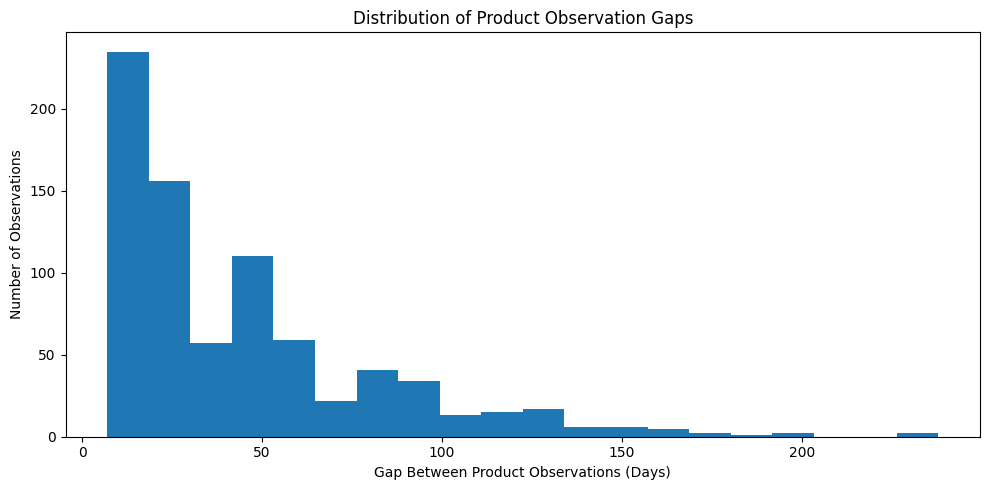

In [43]:
plt.figure(figsize=(10, 5))

plt.hist(
    gap_df["Gap_Days"].dropna(),
    bins=20
)

plt.xlabel("Gap Between Product Observations (Days)")
plt.ylabel("Number of Observations")
plt.title("Distribution of Product Observation Gaps")

plt.tight_layout()
plt.show()

In [44]:
gap_df["Gap_Days"].describe()

count    783.000000
mean      43.242656
std       38.186912
min        7.000000
25%       14.000000
50%       35.000000
75%       56.000000
max      238.000000
Name: Gap_Days, dtype: float64

In [45]:
gap_df["Gap_Days"].value_counts().sort_index().head(20)

Gap_Days
7.0      128
14.0     107
21.0      91
28.0      65
35.0      57
42.0      66
49.0      44
56.0      34
63.0      25
70.0      22
77.0      21
84.0      20
91.0      19
98.0      15
105.0     13
112.0      8
119.0      7
126.0      7
133.0     10
140.0      6
Name: count, dtype: int64

In [46]:
required_columns = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Target_Next_Week"
]
model_df = weekly_df.dropna(
    subset=required_columns
).copy()
model_df["Catagory"] = model_df["Catagory"].fillna("Unknown")
print("Original weekly records:", len(weekly_df))
print("Model-ready records:", len(model_df))
print("Rows removed:", len(weekly_df) - len(model_df))

Original weekly records: 904
Model-ready records: 315
Rows removed: 589


In [47]:
print("\nRemaining missing values:")
print(model_df.isnull().sum())


Remaining missing values:
Product_Name        0
Week                0
Sales_Volume        0
Stock_Quantity      0
Reorder_Level       0
Reorder_Quantity    0
Unit_Price          0
Catagory            0
Lag_1               0
Lag_2               0
Lag_3               0
Lag_4               0
Rolling_Mean_4      0
Rolling_Std_4       0
Target_Next_Week    0
dtype: int64


In [48]:
model_df.head(10)

,Product_Name,Week,Sales_Volume,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Catagory,Lag_1,Lag_2,Lag_3,Lag_4,Rolling_Mean_4,Rolling_Std_4,Target_Next_Week
7,Almond Flour,2024-10-28,38,37.0,47.0,34.0,9.5,Grains & Pulses,26.0,43.0,60.0,24.0,38.25,16.820127,24.0
8,Almond Flour,2024-11-04,24,76.0,8.0,2.0,9.5,Grains & Pulses,38.0,26.0,43.0,60.0,41.75,14.103782,56.0
9,Almond Flour,2024-12-09,56,12.0,56.0,92.0,9.5,Grains & Pulses,24.0,38.0,26.0,43.0,32.75,9.215024,51.0
10,Almond Flour,2025-01-20,51,75.5,20.5,61.0,9.5,Grains & Pulses,56.0,24.0,38.0,26.0,36.00,14.696938,83.0
16,Anchovies,2024-05-06,80,51.0,35.0,95.0,10.0,Seafood,49.0,80.0,98.0,34.0,65.25,29.044506,81.0
17,Anchovies,2024-06-10,81,93.0,51.0,70.0,10.0,Seafood,80.0,49.0,80.0,98.0,76.75,20.353132,70.0
18,Anchovies,2024-07-08,70,84.5,36.0,67.5,10.0,Seafood,81.0,80.0,49.0,80.0,72.50,15.673757,27.0
19,Anchovies,2024-10-07,27,66.0,49.0,41.0,10.0,Seafood,70.0,81.0,80.0,49.0,70.00,14.854853,54.0
20,Anchovies,2024-10-21,54,100.0,99.0,8.0,10.0,Seafood,27.0,70.0,81.0,80.0,64.50,25.488560,95.0
26,Apple,2025-01-06,41,44.0,92.0,92.0,3.5,Fruits & Vegetables,39.0,87.0,102.0,63.0,72.75,27.645072,42.0


In [49]:
print("Model dataset shape:", model_df.shape)

Model dataset shape: (315, 15)


In [50]:
model_df.dtypes

Product_Name                object
Week                datetime64[ns]
Sales_Volume                 int64
Stock_Quantity             float64
Reorder_Level              float64
Reorder_Quantity           float64
Unit_Price                 float64
Catagory                    object
Lag_1                      float64
Lag_2                      float64
Lag_3                      float64
Lag_4                      float64
Rolling_Mean_4             float64
Rolling_Std_4              float64
Target_Next_Week           float64
dtype: object

In [51]:
product_mapping = {
    product: idx
    for idx, product in enumerate(
        model_df["Product_Name"].unique()
    )
}
category_mapping = {
    category: idx
    for idx, category in enumerate(
        model_df["Catagory"].unique()
    )
}
model_df["Product_ID"] = model_df["Product_Name"].map(product_mapping)
model_df["Category_ID"] = model_df["Catagory"].map(category_mapping)

print("Number of products:", model_df["Product_ID"].nunique())
print("Number of categories:", model_df["Category_ID"].nunique())

model_df[
    ["Product_Name", "Product_ID", "Catagory", "Category_ID"]
].head(10)

Number of products: 98
Number of categories: 8


,Product_Name,Product_ID,Catagory,Category_ID
7,Almond Flour,0,Grains & Pulses,0
8,Almond Flour,0,Grains & Pulses,0
9,Almond Flour,0,Grains & Pulses,0
10,Almond Flour,0,Grains & Pulses,0
16,Anchovies,1,Seafood,1
17,Anchovies,1,Seafood,1
18,Anchovies,1,Seafood,1
19,Anchovies,1,Seafood,1
20,Anchovies,1,Seafood,1
26,Apple,2,Fruits & Vegetables,2


In [52]:
feature_columns = [
    "Product_ID",
    "Category_ID",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

target_column = "Target_Next_Week"

print("Features:")
print(feature_columns)

print("\nTarget:")
print(target_column)

Features:
['Product_ID', 'Category_ID', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_4', 'Rolling_Mean_4', 'Rolling_Std_4', 'Stock_Quantity', 'Reorder_Level', 'Reorder_Quantity', 'Unit_Price']

Target:
Target_Next_Week


In [53]:
output_path = "../data/model_ready_weekly.csv"

model_df.to_csv(
    output_path,
    index=False
)

print("Saved successfully:")
print(output_path)

Saved successfully:
../data/model_ready_weekly.csv


In [54]:
model_df = model_df.sort_values("Week").reset_index(drop=True)
n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()
print("Total records :", len(model_df))
print("Training      :", len(train_df))
print("Validation    :", len(val_df))
print("Testing       :", len(test_df))

Total records : 315
Training      : 220
Validation    : 47
Testing       : 48


In [55]:
print("TRAIN")
print(train_df["Week"].min(), "to", train_df["Week"].max())

print("\nVALIDATION")
print(val_df["Week"].min(), "to", val_df["Week"].max())

print("\nTEST")
print(test_df["Week"].min(), "to", test_df["Week"].max())

TRAIN
2024-04-22 00:00:00 to 2024-11-25 00:00:00

VALIDATION
2024-12-02 00:00:00 to 2025-01-06 00:00:00

TEST
2025-01-06 00:00:00 to 2025-02-10 00:00:00


In [56]:
unique_weeks = sorted(model_df["Week"].unique())

n_weeks = len(unique_weeks)

train_week_end = int(n_weeks * 0.70)
val_week_end = int(n_weeks * 0.85)

train_weeks = unique_weeks[:train_week_end]
val_weeks = unique_weeks[train_week_end:val_week_end]
test_weeks = unique_weeks[val_week_end:]

train_df = model_df[
    model_df["Week"].isin(train_weeks)
].copy()

val_df = model_df[
    model_df["Week"].isin(val_weeks)
].copy()

test_df = model_df[
    model_df["Week"].isin(test_weeks)
].copy()

print("Total records :", len(model_df))
print("Training      :", len(train_df))
print("Validation    :", len(val_df))
print("Testing       :", len(test_df))

print("\nNumber of unique weeks:")
print("Training      :", len(train_weeks))
print("Validation    :", len(val_weeks))
print("Testing       :", len(test_weeks))

Total records : 315
Training      : 188
Validation    : 73
Testing       : 54

Number of unique weeks:
Training      : 29
Validation    : 6
Testing       : 7


In [57]:
print("\nTRAIN")
print(train_df["Week"].min(), "to", train_df["Week"].max())

print("\nVALIDATION")
print(val_df["Week"].min(), "to", val_df["Week"].max())

print("\nTEST")
print(test_df["Week"].min(), "to", test_df["Week"].max())


TRAIN
2024-04-22 00:00:00 to 2024-11-11 00:00:00

VALIDATION
2024-11-18 00:00:00 to 2024-12-23 00:00:00

TEST
2024-12-30 00:00:00 to 2025-02-10 00:00:00


In [58]:
print("TRAIN")
print(train_df["Week"].min(), "to", train_df["Week"].max())

print("\nVALIDATION")
print(val_df["Week"].min(), "to", val_df["Week"].max())

print("\nTEST")
print(test_df["Week"].min(), "to", test_df["Week"].max())

TRAIN
2024-04-22 00:00:00 to 2024-11-11 00:00:00

VALIDATION
2024-11-18 00:00:00 to 2024-12-23 00:00:00

TEST
2024-12-30 00:00:00 to 2025-02-10 00:00:00


In [69]:
from sklearn.preprocessing import StandardScaler
numerical_features = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]


scaler = StandardScaler()

train_df[numerical_features] = scaler.fit_transform(
    train_df[numerical_features]
)


val_df[numerical_features] = scaler.transform(
    val_df[numerical_features]
)

test_df[numerical_features] = scaler.transform(
    test_df[numerical_features]
)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [70]:
print("Training feature means:")
print(train_df[numerical_features].mean().round(3))

print("\nTraining feature standard deviations:")
print(train_df[numerical_features].std().round(3))

Training feature means:
Lag_1              -0.0
Lag_2               0.0
Lag_3               0.0
Lag_4               0.0
Rolling_Mean_4      0.0
Rolling_Std_4       0.0
Stock_Quantity     -0.0
Reorder_Level       0.0
Reorder_Quantity   -0.0
Unit_Price         -0.0
dtype: float64

Training feature standard deviations:
Lag_1               1.003
Lag_2               1.003
Lag_3               1.003
Lag_4               1.003
Rolling_Mean_4      1.003
Rolling_Std_4       1.003
Stock_Quantity      1.003
Reorder_Level       1.003
Reorder_Quantity    1.003
Unit_Price          1.003
dtype: float64


In [71]:
print("Validation sample:")
display(val_df[numerical_features].head())

print("\nTest sample:")
display(test_df[numerical_features].head())

Validation sample:


,Lag_1,Lag_2,Lag_3,Lag_4,Rolling_Mean_4,Rolling_Std_4,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price
188,-0.259629,0.371570,-0.094742,-0.691984,-0.311118,-0.940655,-1.128793,1.424136,-0.678715,-0.648777
189,-0.728657,-0.775577,-0.094742,-0.691984,-1.194305,-1.180857,-1.048432,-0.859999,-0.963666,-0.152237
190,1.053650,-0.443508,0.194093,0.746477,0.772034,-0.486235,-0.405545,-1.752240,-1.319854,-0.589192
191,-0.634851,0.522511,-1.217987,1.027153,-0.194471,0.178459,0.357884,0.603275,-0.108814,-0.847393
192,0.428279,0.522511,2.986158,1.202575,2.638390,0.598732,-1.289514,0.282068,0.033661,0.443611



Test sample:


,Lag_1,Lag_2,Lag_3,Lag_4,Rolling_Mean_4,Rolling_Std_4,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price
261,2.679614,-0.020875,-0.223113,0.360549,1.471918,1.043214,1.081132,1.459825,0.461087,0.185410
262,0.678428,-0.383132,1.028503,0.711393,1.021993,-0.577595,-1.852041,-0.824310,-1.497948,-0.549469
263,-0.040749,-0.292567,0.418742,1.342913,0.672051,-0.535277,0.679327,-1.181206,0.425468,-0.748085
264,-0.634851,0.281006,-1.314265,0.255295,-0.744380,-0.312527,0.377974,1.031550,0.087089,-0.231683
265,0.021788,0.945144,-1.314265,0.255295,-0.027832,0.123004,-1.771680,1.709653,1.565270,-0.311130


In [72]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
baseline_predictions = test_df["Lag_1"].copy()


lag1_mean = scaler.mean_[numerical_features.index("Lag_1")]
lag1_std = scaler.scale_[numerical_features.index("Lag_1")]

baseline_predictions_original = (
    baseline_predictions * lag1_std + lag1_mean
)
actual = test_df["Target_Next_Week"]
mae = mean_absolute_error(
    actual,
    baseline_predictions_original
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        baseline_predictions_original
    )
)

print("Naive Baseline Results")
print("----------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

Naive Baseline Results
----------------------
MAE : 32.41
RMSE: 42.78


In [73]:
wape = (
    np.sum(
        np.abs(
            actual - baseline_predictions_original
        )
    )
    /
    np.sum(
        np.abs(actual)
    )
) * 100

print("WAPE:", round(wape, 2), "%")

WAPE: 53.63 %


In [74]:


smape = (
    np.mean(
        2 * np.abs(
            actual - baseline_predictions_original
        )
        /
        (
            np.abs(actual)
            +
            np.abs(baseline_predictions_original)
            +
            1e-8
        )
    )
) * 100

print("sMAPE:", round(smape, 2), "%")

sMAPE: 50.97 %


In [75]:
baseline_results = {
    "Model": "Naive Baseline",
    "MAE": mae,
    "RMSE": rmse,
    "WAPE": wape,
    "sMAPE": smape
}

print(baseline_results)

{'Model': 'Naive Baseline', 'MAE': 32.407407407407405, 'RMSE': np.float64(42.78196227729972), 'WAPE': np.float64(53.631627336806616), 'sMAPE': np.float64(50.96957410172208)}


In [76]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.12.0+cpu
Training device: cpu


In [77]:
mlp_features = [
    "Product_ID",
    "Category_ID",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

target = "Target_Next_Week"

X_train = train_df[mlp_features].values
y_train = train_df[target].values

X_val = val_df[mlp_features].values
y_val = val_df[target].values

X_test = test_df[mlp_features].values
y_test = test_df[target].values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (188, 12)
y_train: (188,)
X_val: (73, 12)
y_val: (73,)
X_test: (54, 12)
y_test: (54,)


In [78]:
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
).view(-1, 1)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.float32
).view(-1, 1)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
).view(-1, 1)

print("Tensors created successfully!")

Tensors created successfully!


In [79]:


batch_size = 16

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Batch size:", batch_size)

DataLoaders created successfully!
Batch size: 16


In [80]:
class DemandMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)
mlp_model = DemandMLP(
    input_size=len(mlp_features)
).to(device)

print(mlp_model)

DemandMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=16, bias=True)
    (6): ReLU()
    (7): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [81]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [82]:

num_epochs = 100

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    
    mlp_model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

      
        optimizer.zero_grad()

       
        predictions = mlp_model(X_batch)

       
        loss = criterion(predictions, y_batch)

        
        loss.backward()

       
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = (
        running_train_loss / len(train_loader.dataset)
    )

   
    mlp_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = mlp_model(X_batch)

            loss = criterion(predictions, y_batch)

            running_val_loss += (
                loss.item() * X_batch.size(0)
            )

    epoch_val_loss = (
        running_val_loss / len(val_loader.dataset)
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

  
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Val Loss: {epoch_val_loss:.4f}"
        )

Epoch [10/100] Train Loss: 1735.0726 Val Loss: 1712.9603
Epoch [20/100] Train Loss: 1487.1916 Val Loss: 1536.7023
Epoch [30/100] Train Loss: 1213.4950 Val Loss: 1412.8196
Epoch [40/100] Train Loss: 1041.6845 Val Loss: 1383.2429
Epoch [50/100] Train Loss: 950.1106 Val Loss: 1289.7389
Epoch [60/100] Train Loss: 881.9470 Val Loss: 1198.0419
Epoch [70/100] Train Loss: 852.5868 Val Loss: 1090.4159
Epoch [80/100] Train Loss: 783.1971 Val Loss: 1039.9828
Epoch [90/100] Train Loss: 785.2446 Val Loss: 990.0304
Epoch [100/100] Train Loss: 749.9788 Val Loss: 985.9766


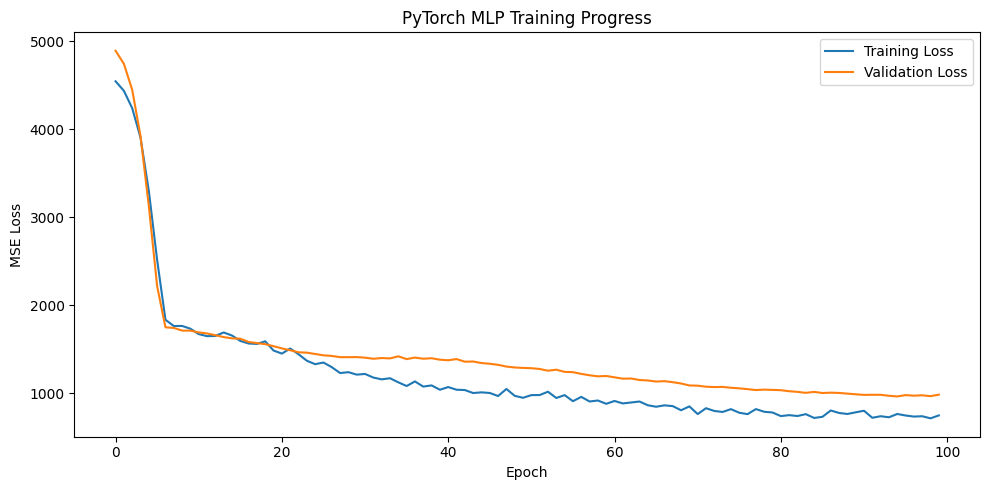

In [83]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PyTorch MLP Training Progress")

plt.legend()
plt.tight_layout()
plt.show()

In [84]:
mlp_model.eval()
val_predictions = []

with torch.no_grad():

    for X_batch, _ in val_loader:

        X_batch = X_batch.to(device)

        predictions = mlp_model(X_batch)

        val_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

val_predictions = np.array(val_predictions)

print("Validation predictions:", val_predictions.shape)
print("Actual validation values:", y_val.shape)

Validation predictions: (73,)
Actual validation values: (73,)


In [85]:


val_mae = mean_absolute_error(
    y_val,
    val_predictions
)

val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        val_predictions
    )
)

val_wape = (
    np.sum(np.abs(y_val - val_predictions))
    /
    np.sum(np.abs(y_val))
) * 100

val_smape = (
    np.mean(
        2 * np.abs(y_val - val_predictions)
        /
        (
            np.abs(y_val)
            + np.abs(val_predictions)
            + 1e-8
        )
    )
) * 100

print("MLP Validation Results")
print("----------------------")
print("MAE  :", round(val_mae, 2))
print("RMSE :", round(val_rmse, 2))
print("WAPE :", round(val_wape, 2), "%")
print("sMAPE:", round(val_smape, 2), "%")

MLP Validation Results
----------------------
MAE  : 24.97
RMSE : 31.4
WAPE : 38.63 %
sMAPE: 39.96 %


In [86]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "PyTorch MLP"
    ],
    "MAE": [
        mae,
        val_mae
    ],
    "RMSE": [
        rmse,
        val_rmse
    ],
    "WAPE": [
        wape,
        val_wape
    ],
    "sMAPE": [
        smape,
        val_smape
    ]
})

comparison

,Model,MAE,RMSE,WAPE,sMAPE
0,Naive Baseline,32.407407,42.781962,53.631627,50.969574
1,PyTorch MLP,24.969781,31.400264,38.634889,39.957155


In [87]:

sequence_length = 4

print("LSTM sequence length:", sequence_length)

LSTM sequence length: 4


In [88]:


sequence_counts = (
    model_df.groupby("Product_ID")
    .size()
    .sort_values(ascending=False)
)

print("Product sequence statistics:")
print(sequence_counts.describe())

print("\nLongest product sequences:")
print(sequence_counts.head(10))

Product sequence statistics:
count    98.000000
mean      3.214286
std       2.106690
min       1.000000
25%       2.000000
50%       3.000000
75%       4.000000
max      11.000000
dtype: float64

Longest product sequences:
Product_ID
14    11
4     10
21     9
44     9
39     8
69     8
58     7
33     7
9      6
92     6
dtype: int64


In [89]:
sequence_counts.describe()

count    98.000000
mean      3.214286
std       2.106690
min       1.000000
25%       2.000000
50%       3.000000
75%       4.000000
max      11.000000
dtype: float64

In [90]:


original_counts = (
    product_weekly
    .groupby("Product_Name")
    .size()
    .sort_values(ascending=False)
)

print("Original product history statistics:")
print(original_counts.describe())

print("\nProducts with at least 5 observations:")
print(
    (original_counts >= 5).sum()
)

print("\nProducts with at least 4 observations:")
print(
    (original_counts >= 4).sum()
)

Original product history statistics:
count    121.000000
mean       7.471074
std        2.463312
min        3.000000
25%        6.000000
50%        7.000000
75%        9.000000
max       16.000000
dtype: float64

Products with at least 5 observations:
109

Products with at least 4 observations:
117


In [91]:


for length in [3, 4, 5]:

    possible_sequences = (
        original_counts - length + 1
    ).clip(lower=0)

    print(
        f"Sequence length {length}: "
        f"{possible_sequences.sum()} possible windows"
    )

Sequence length 3: 662 possible windows
Sequence length 4: 541 possible windows
Sequence length 5: 424 possible windows


In [92]:
lstm_df = product_weekly.copy()
lstm_df = lstm_df.sort_values(
    ["Product_Name", "Week"]
).reset_index(drop=True)


lstm_df["Gap_Days"] = (
    lstm_df.groupby("Product_Name")["Week"]
    .diff()
    .dt.days
)


lstm_df["Gap_Days"] = (
    lstm_df["Gap_Days"]
    .fillna(0)
)

print("LSTM source shape:", lstm_df.shape)

lstm_df.head(10)

LSTM source shape: (904, 4)


,Product_Name,Week,Sales_Volume,Gap_Days
0,All-Purpose Flour,2024-05-20,34,0.0
1,All-Purpose Flour,2024-11-04,77,168.0
2,All-Purpose Flour,2025-02-17,87,105.0
3,Almond Flour,2024-05-13,24,0.0
4,Almond Flour,2024-08-05,60,84.0
5,Almond Flour,2024-09-30,43,56.0
6,Almond Flour,2024-10-21,26,21.0
7,Almond Flour,2024-10-28,38,7.0
8,Almond Flour,2024-11-04,24,7.0
9,Almond Flour,2024-12-09,56,35.0


In [93]:
lstm_df["Product_ID"] = (
    lstm_df["Product_Name"]
    .map(product_mapping)
)

print(
    "Unique products:",
    lstm_df["Product_ID"].nunique()
)

Unique products: 98


In [94]:
sequence_length = 4
sequence_data = []
sequence_targets = []
sequence_products = []
sequence_dates = []

for product_name, group in lstm_df.groupby("Product_Name"):

    group = group.sort_values("Week").reset_index(drop=True)

    sales = group["Sales_Volume"].values
    gaps = group["Gap_Days"].values
    product_id = group["Product_ID"].iloc[0]
    for i in range(len(group) - sequence_length):

        sales_sequence = sales[
            i:i + sequence_length
        ]

        gap_sequence = gaps[
            i:i + sequence_length
        ]

        features = np.column_stack([
            sales_sequence,
            gap_sequence
        ])

        target_value = sales[
            i + sequence_length
        ]

        sequence_data.append(features)
        sequence_targets.append(target_value)
        sequence_products.append(product_id)
        sequence_dates.append(
            group["Week"].iloc[i + sequence_length]
        )

X_lstm = np.array(sequence_data)
y_lstm = np.array(sequence_targets)

print("LSTM input shape:", X_lstm.shape)
print("LSTM target shape:", y_lstm.shape)
print("Number of sequences:", len(X_lstm))

LSTM input shape: (424, 4, 2)
LSTM target shape: (424,)
Number of sequences: 424


In [95]:
all_products = sorted(
    product_weekly["Product_Name"].unique()
)

lstm_product_mapping = {
    product: idx
    for idx, product in enumerate(all_products)
}
lstm_df["Product_ID"] = (
    lstm_df["Product_Name"]
    .map(lstm_product_mapping)
)

print("Total products in original data:",
      len(all_products))

print("Unique Product IDs in LSTM data:",
      lstm_df["Product_ID"].nunique())

Total products in original data: 121
Unique Product IDs in LSTM data: 121


In [96]:
sequence_dates = np.array(sequence_dates)
sort_idx = np.argsort(sequence_dates)
X_lstm = X_lstm[sort_idx]
y_lstm = y_lstm[sort_idx]
sequence_dates = sequence_dates[sort_idx]
n_sequences = len(X_lstm)
train_end = int(n_sequences * 0.70)
val_end = int(n_sequences * 0.85)
X_lstm_train = X_lstm[:train_end]
y_lstm_train = y_lstm[:train_end]
dates_lstm_train = sequence_dates[:train_end]
X_lstm_val = X_lstm[train_end:val_end]
y_lstm_val = y_lstm[train_end:val_end]
dates_lstm_val = sequence_dates[train_end:val_end]
X_lstm_test = X_lstm[val_end:]
y_lstm_test = y_lstm[val_end:]
dates_lstm_test = sequence_dates[val_end:]
print("LSTM train:", X_lstm_train.shape)
print("LSTM validation:", X_lstm_val.shape)
print("LSTM test:", X_lstm_test.shape)

LSTM train: (296, 4, 2)
LSTM validation: (64, 4, 2)
LSTM test: (64, 4, 2)


In [97]:
print("TRAIN")
print(dates_lstm_train.min(), "to", dates_lstm_train.max())
print("\nVALIDATION")
print(dates_lstm_val.min(), "to", dates_lstm_val.max())
print("\nTEST")
print(dates_lstm_test.min(), "to", dates_lstm_test.max())

TRAIN
2024-04-22 00:00:00 to 2025-01-06 00:00:00

VALIDATION
2025-01-06 00:00:00 to 2025-01-27 00:00:00

TEST
2025-02-03 00:00:00 to 2025-02-24 00:00:00


In [98]:
from sklearn.preprocessing import StandardScaler
lstm_scaler = StandardScaler()
train_2d = X_lstm_train.reshape(-1, 2)
lstm_scaler.fit(train_2d)
X_lstm_train_scaled = lstm_scaler.transform(
    X_lstm_train.reshape(-1, 2)
).reshape(X_lstm_train.shape)
X_lstm_val_scaled = lstm_scaler.transform(
    X_lstm_val.reshape(-1, 2)
).reshape(X_lstm_val.shape)
X_lstm_test_scaled = lstm_scaler.transform(
    X_lstm_test.reshape(-1, 2)
).reshape(X_lstm_test.shape)
print("LSTM feature scaling completed!")
print("Training shape:", X_lstm_train_scaled.shape)
print("Validation shape:", X_lstm_val_scaled.shape)
print("Test shape:", X_lstm_test_scaled.shape)

LSTM feature scaling completed!
Training shape: (296, 4, 2)
Validation shape: (64, 4, 2)
Test shape: (64, 4, 2)


In [99]:
print("Training scaled means:")
print(
    X_lstm_train_scaled
    .reshape(-1, 2)
    .mean(axis=0)
)
print("\nTraining scaled standard deviations:")
print(
    X_lstm_train_scaled
    .reshape(-1, 2)
    .std(axis=0)
)

Training scaled means:
[-2.20169228e-16 -8.27509982e-16]

Training scaled standard deviations:
[1. 1.]


In [100]:
X_lstm_train_tensor = torch.tensor(
    X_lstm_train_scaled,
    dtype=torch.float32
)
y_lstm_train_tensor = torch.tensor(
    y_lstm_train,
    dtype=torch.float32
).view(-1, 1)

X_lstm_val_tensor = torch.tensor(
    X_lstm_val_scaled,
    dtype=torch.float32
)

y_lstm_val_tensor = torch.tensor(
    y_lstm_val,
    dtype=torch.float32
).view(-1, 1)

X_lstm_test_tensor = torch.tensor(
    X_lstm_test_scaled,
    dtype=torch.float32
)

y_lstm_test_tensor = torch.tensor(
    y_lstm_test,
    dtype=torch.float32
).view(-1, 1)

print("LSTM tensors created successfully!")


LSTM tensors created successfully!


In [101]:
lstm_batch_size = 16
lstm_train_dataset = TensorDataset(
    X_lstm_train_tensor,
    y_lstm_train_tensor
)

lstm_val_dataset = TensorDataset(
    X_lstm_val_tensor,
    y_lstm_val_tensor
)

lstm_test_dataset = TensorDataset(
    X_lstm_test_tensor,
    y_lstm_test_tensor
)

lstm_train_loader = DataLoader(
    lstm_train_dataset,
    batch_size=lstm_batch_size,
    shuffle=True
)

lstm_val_loader = DataLoader(
    lstm_val_dataset,
    batch_size=lstm_batch_size,
    shuffle=False
)

lstm_test_loader = DataLoader(
    lstm_test_dataset,
    batch_size=lstm_batch_size,
    shuffle=False
)

print("LSTM DataLoaders created!")
print("Batch size:", lstm_batch_size)

LSTM DataLoaders created!
Batch size: 16


In [102]:
class DemandLSTM(nn.Module):

    def __init__(
        self,
        input_size=2,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        lstm_output, _ = self.lstm(x)
        last_output = lstm_output[:, -1, :]
        output = self.fc(last_output)
        return output

lstm_model = DemandLSTM(
    input_size=2,
    hidden_size=64,
    num_layers=2,
    dropout=0.2
).to(device)

print(lstm_model)

DemandLSTM(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [103]:
lstm_criterion = nn.MSELoss()
lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("LSTM loss:", lstm_criterion)
print("LSTM optimizer:", lstm_optimizer)

LSTM loss: MSELoss()
LSTM optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [104]:
num_epochs_lstm = 100
lstm_train_losses = []
lstm_val_losses = []

for epoch in range(num_epochs_lstm):
    lstm_model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in lstm_train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        lstm_optimizer.zero_grad()

        predictions = lstm_model(X_batch)

        loss = lstm_criterion(
            predictions,
            y_batch
        )

        loss.backward()

        
        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        lstm_optimizer.step()

        running_train_loss += (
            loss.item() * X_batch.size(0)
        )

    epoch_train_loss = (
        running_train_loss
        / len(lstm_train_loader.dataset)
    )

    
    lstm_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in lstm_val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = lstm_model(X_batch)

            loss = lstm_criterion(
                predictions,
                y_batch
            )

            running_val_loss += (
                loss.item() * X_batch.size(0)
            )

    epoch_val_loss = (
        running_val_loss
        / len(lstm_val_loader.dataset)
    )

    lstm_train_losses.append(
        epoch_train_loss
    )

    lstm_val_losses.append(
        epoch_val_loss
    )

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{num_epochs_lstm}] "
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Val Loss: {epoch_val_loss:.4f}"
        )

Epoch [10/100] Train Loss: 1519.4174 Val Loss: 1681.1936
Epoch [20/100] Train Loss: 951.7498 Val Loss: 1053.4444
Epoch [30/100] Train Loss: 909.6042 Val Loss: 1035.8798
Epoch [40/100] Train Loss: 865.7586 Val Loss: 1035.6596
Epoch [50/100] Train Loss: 856.2376 Val Loss: 1059.1861
Epoch [60/100] Train Loss: 841.1882 Val Loss: 1099.5488
Epoch [70/100] Train Loss: 895.5085 Val Loss: 1100.5662
Epoch [80/100] Train Loss: 817.5311 Val Loss: 1130.3582
Epoch [90/100] Train Loss: 880.1023 Val Loss: 1096.7624
Epoch [100/100] Train Loss: 853.4375 Val Loss: 1096.3382


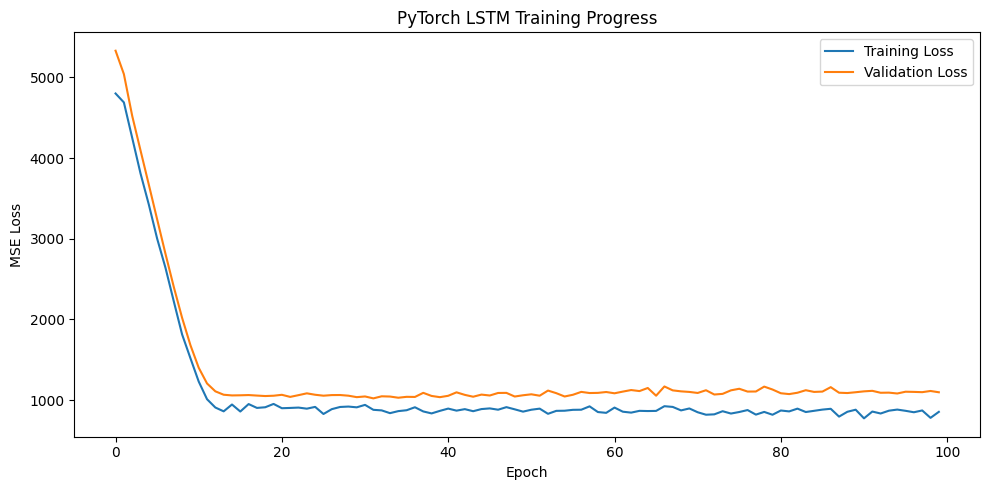

In [105]:

plt.figure(figsize=(10, 5))

plt.plot(
    lstm_train_losses,
    label="Training Loss"
)

plt.plot(
    lstm_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PyTorch LSTM Training Progress")

plt.legend()
plt.tight_layout()
plt.show()

In [106]:


lstm_model.eval()

lstm_val_predictions = []

with torch.no_grad():

    for X_batch, _ in lstm_val_loader:

        X_batch = X_batch.to(device)

        predictions = lstm_model(X_batch)

        lstm_val_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

lstm_val_predictions = np.array(
    lstm_val_predictions
)

print(
    "LSTM validation predictions:",
    lstm_val_predictions.shape
)

print(
    "Actual validation values:",
    y_lstm_val.shape
)

LSTM validation predictions: (64,)
Actual validation values: (64,)


In [107]:
lstm_val_mae = mean_absolute_error(
    y_lstm_val,
    lstm_val_predictions
)

lstm_val_rmse = np.sqrt(
    mean_squared_error(
        y_lstm_val,
        lstm_val_predictions
    )
)

lstm_val_wape = (
    np.sum(
        np.abs(
            y_lstm_val - lstm_val_predictions
        )
    )
    /
    np.sum(
        np.abs(y_lstm_val)
    )
) * 100

lstm_val_smape = (
    np.mean(
        2 * np.abs(
            y_lstm_val - lstm_val_predictions
        )
        /
        (
            np.abs(y_lstm_val)
            + np.abs(lstm_val_predictions)
            + 1e-8
        )
    )
) * 100

print("LSTM Validation Results")
print("-----------------------")
print("MAE  :", round(lstm_val_mae, 2))
print("RMSE :", round(lstm_val_rmse, 2))
print("WAPE :", round(lstm_val_wape, 2), "%")
print("sMAPE:", round(lstm_val_smape, 2), "%")

LSTM Validation Results
-----------------------
MAE  : 26.15
RMSE : 33.11
WAPE : 39.65 %
sMAPE: 41.23 %


In [108]:
model_comparison = pd.DataFrame({
    "Model": [
        "PyTorch MLP",
        "PyTorch LSTM"
    ],
    "MAE": [
        val_mae,
        lstm_val_mae
    ],
    "RMSE": [
        val_rmse,
        lstm_val_rmse
    ],
    "WAPE": [
        val_wape,
        lstm_val_wape
    ],
    "sMAPE": [
        val_smape,
        lstm_val_smape
    ]
})

model_comparison

,Model,MAE,RMSE,WAPE,sMAPE
0,PyTorch MLP,24.969781,31.400264,38.634889,39.957155
1,PyTorch LSTM,26.153225,33.110997,39.654261,41.234423


In [109]:
# ==========================================
# STEP 51: HYBRID SEQUENCE SOURCE
# ==========================================

hybrid_df = df.copy()

# Weekly period
hybrid_df["Week"] = (
    hybrid_df["Last_Order_Date"]
    .dt.to_period("W")
    .apply(lambda x: x.start_time)
)

# Aggregate product-level weekly information
hybrid_df = (
    hybrid_df.groupby(
        ["Product_Name", "Week"]
    )
    .agg({
        "Sales_Volume": "sum",
        "Stock_Quantity": "mean",
        "Reorder_Level": "mean",
        "Reorder_Quantity": "mean",
        "Unit_Price": "first",
        "Catagory": "first"
    })
    .reset_index()
)

# Sort
hybrid_df = hybrid_df.sort_values(
    ["Product_Name", "Week"]
).reset_index(drop=True)

# Time gap
hybrid_df["Gap_Days"] = (
    hybrid_df
    .groupby("Product_Name")["Week"]
    .diff()
    .dt.days
    .fillna(0)
)

# Fill missing category
hybrid_df["Catagory"] = (
    hybrid_df["Catagory"]
    .fillna("Unknown")
)

# Convert price
hybrid_df["Unit_Price"] = (
    hybrid_df["Unit_Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

print("Hybrid source shape:", hybrid_df.shape)
print(hybrid_df.head())

Hybrid source shape: (904, 9)
        Product_Name       Week  Sales_Volume  Stock_Quantity  Reorder_Level  \
0  All-Purpose Flour 2024-05-20            34            55.0           33.0   
1  All-Purpose Flour 2024-11-04            77            54.0           69.0   
2  All-Purpose Flour 2025-02-17            87            50.0           42.0   
3       Almond Flour 2024-05-13            24            13.0           88.0   
4       Almond Flour 2024-08-05            60            54.0           17.0   

   Reorder_Quantity  Unit_Price         Catagory  Gap_Days  
0              14.0        1.75  Grains & Pulses       0.0  
1              68.0        1.75  Grains & Pulses     168.0  
2              20.0        1.75  Grains & Pulses     105.0  
3               7.0        9.50  Grains & Pulses       0.0  
4              90.0        9.50  Grains & Pulses      84.0  


In [110]:
# ==========================================
# STEP 52: BUILD HYBRID SEQUENCES
# ==========================================

hybrid_features = [
    "Sales_Volume",
    "Gap_Days",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

sequence_length = 4

hybrid_sequences = []
hybrid_targets = []
hybrid_products = []
hybrid_dates = []

for product_name, group in hybrid_df.groupby("Product_Name"):

    group = group.sort_values("Week").reset_index(drop=True)

    feature_values = group[hybrid_features].values
    target_values = group["Sales_Volume"].values
    product_id = lstm_product_mapping[product_name]

    for i in range(len(group) - sequence_length):

        sequence = feature_values[
            i:i + sequence_length
        ]

        target_value = target_values[
            i + sequence_length
        ]

        hybrid_sequences.append(sequence)
        hybrid_targets.append(target_value)
        hybrid_products.append(product_id)
        hybrid_dates.append(
            group["Week"].iloc[i + sequence_length]
        )

X_hybrid = np.array(hybrid_sequences)
y_hybrid = np.array(hybrid_targets)

product_ids_hybrid = np.array(hybrid_products)
dates_hybrid = np.array(hybrid_dates)

print("Hybrid input shape:", X_hybrid.shape)
print("Hybrid target shape:", y_hybrid.shape)
print("Hybrid product IDs:", product_ids_hybrid.shape)
print("Number of hybrid sequences:", len(X_hybrid))

Hybrid input shape: (424, 4, 6)
Hybrid target shape: (424,)
Hybrid product IDs: (424,)
Number of hybrid sequences: 424


In [111]:
print("First sequence:")
print(X_hybrid[0])

print("\nFirst target:")
print(y_hybrid[0])

print("\nFirst product ID:")
print(product_ids_hybrid[0])

print("\nFirst target date:")
print(dates_hybrid[0])

First sequence:
[[24.   0.  13.  88.   7.   9.5]
 [60.  84.  54.  17.  90.   9.5]
 [43.  56.  75.  46.  75.   9.5]
 [26.  21.  85.  12.  94.   9.5]]

First target:
38

First product ID:
1

First target date:
2024-10-28 00:00:00


In [112]:

sort_idx = np.argsort(dates_hybrid)

X_hybrid = X_hybrid[sort_idx]
y_hybrid = y_hybrid[sort_idx]
product_ids_hybrid = product_ids_hybrid[sort_idx]
dates_hybrid = dates_hybrid[sort_idx]

# 70% / 15% / 15%
n_hybrid = len(X_hybrid)

train_end_hybrid = int(n_hybrid * 0.70)
val_end_hybrid = int(n_hybrid * 0.85)

X_hybrid_train = X_hybrid[:train_end_hybrid]
y_hybrid_train = y_hybrid[:train_end_hybrid]
product_hybrid_train = product_ids_hybrid[:train_end_hybrid]
dates_hybrid_train = dates_hybrid[:train_end_hybrid]

X_hybrid_val = X_hybrid[train_end_hybrid:val_end_hybrid]
y_hybrid_val = y_hybrid[train_end_hybrid:val_end_hybrid]
product_hybrid_val = product_ids_hybrid[train_end_hybrid:val_end_hybrid]
dates_hybrid_val = dates_hybrid[train_end_hybrid:val_end_hybrid]

X_hybrid_test = X_hybrid[val_end_hybrid:]
y_hybrid_test = y_hybrid[val_end_hybrid:]
product_hybrid_test = product_ids_hybrid[val_end_hybrid:]
dates_hybrid_test = dates_hybrid[val_end_hybrid:]

print("Hybrid train:", X_hybrid_train.shape)
print("Hybrid validation:", X_hybrid_val.shape)
print("Hybrid test:", X_hybrid_test.shape)

Hybrid train: (296, 4, 6)
Hybrid validation: (64, 4, 6)
Hybrid test: (64, 4, 6)


In [113]:
print("TRAIN")
print(
    dates_hybrid_train.min(),
    "to",
    dates_hybrid_train.max()
)

print("\nVALIDATION")
print(
    dates_hybrid_val.min(),
    "to",
    dates_hybrid_val.max()
)

print("\nTEST")
print(
    dates_hybrid_test.min(),
    "to",
    dates_hybrid_test.max()
)

TRAIN
2024-04-22 00:00:00 to 2025-01-06 00:00:00

VALIDATION
2025-01-06 00:00:00 to 2025-01-27 00:00:00

TEST
2025-02-03 00:00:00 to 2025-02-24 00:00:00


In [114]:
# ==========================================
# STEP 54: SCALE HYBRID FEATURES
# ==========================================

hybrid_scaler = StandardScaler()

# Flatten training sequences
hybrid_train_2d = X_hybrid_train.reshape(-1, 6)

# Fit only on training data
hybrid_scaler.fit(hybrid_train_2d)

# Transform all splits
X_hybrid_train_scaled = hybrid_scaler.transform(
    X_hybrid_train.reshape(-1, 6)
).reshape(X_hybrid_train.shape)

X_hybrid_val_scaled = hybrid_scaler.transform(
    X_hybrid_val.reshape(-1, 6)
).reshape(X_hybrid_val.shape)

X_hybrid_test_scaled = hybrid_scaler.transform(
    X_hybrid_test.reshape(-1, 6)
).reshape(X_hybrid_test.shape)

print("Hybrid feature scaling completed!")
print(
    "Train:",
    X_hybrid_train_scaled.shape
)

print(
    "Validation:",
    X_hybrid_val_scaled.shape
)

print(
    "Test:",
    X_hybrid_test_scaled.shape
)

Hybrid feature scaling completed!
Train: (296, 4, 6)
Validation: (64, 4, 6)
Test: (64, 4, 6)


In [115]:
# ==========================================
# STEP 55: HYBRID PYTORCH TENSORS
# ==========================================

X_hybrid_train_tensor = torch.tensor(
    X_hybrid_train_scaled,
    dtype=torch.float32
)

y_hybrid_train_tensor = torch.tensor(
    y_hybrid_train,
    dtype=torch.float32
).view(-1, 1)

X_hybrid_val_tensor = torch.tensor(
    X_hybrid_val_scaled,
    dtype=torch.float32
)

y_hybrid_val_tensor = torch.tensor(
    y_hybrid_val,
    dtype=torch.float32
).view(-1, 1)

X_hybrid_test_tensor = torch.tensor(
    X_hybrid_test_scaled,
    dtype=torch.float32
)

y_hybrid_test_tensor = torch.tensor(
    y_hybrid_test,
    dtype=torch.float32
).view(-1, 1)

product_hybrid_train_tensor = torch.tensor(
    product_hybrid_train,
    dtype=torch.long
)

product_hybrid_val_tensor = torch.tensor(
    product_hybrid_val,
    dtype=torch.long
)

product_hybrid_test_tensor = torch.tensor(
    product_hybrid_test,
    dtype=torch.long
)

print("Hybrid tensors created successfully!")

Hybrid tensors created successfully!


In [116]:
# ==========================================
# STEP 56: HYBRID DATALOADERS
# ==========================================

hybrid_batch_size = 16

hybrid_train_dataset = TensorDataset(
    X_hybrid_train_tensor,
    product_hybrid_train_tensor,
    y_hybrid_train_tensor
)

hybrid_val_dataset = TensorDataset(
    X_hybrid_val_tensor,
    product_hybrid_val_tensor,
    y_hybrid_val_tensor
)

hybrid_test_dataset = TensorDataset(
    X_hybrid_test_tensor,
    product_hybrid_test_tensor,
    y_hybrid_test_tensor
)

hybrid_train_loader = DataLoader(
    hybrid_train_dataset,
    batch_size=hybrid_batch_size,
    shuffle=True
)

hybrid_val_loader = DataLoader(
    hybrid_val_dataset,
    batch_size=hybrid_batch_size,
    shuffle=False
)

hybrid_test_loader = DataLoader(
    hybrid_test_dataset,
    batch_size=hybrid_batch_size,
    shuffle=False
)

print("Hybrid DataLoaders created successfully!")
print("Batch size:", hybrid_batch_size)

Hybrid DataLoaders created successfully!
Batch size: 16


In [117]:
num_products = len(all_products)

In [118]:
# ==========================================
# STEP 57: PRODUCT VOCABULARY
# ==========================================

num_products = len(all_products)

print("Number of products:", num_products)
print("Product ID range:",
      product_hybrid_train_tensor.min().item(),
      "to",
      product_hybrid_train_tensor.max().item())

Number of products: 121
Product ID range: 1 to 120


In [119]:
# ==========================================
# STEP 57.1: VERIFY PRODUCT ID MAPPING
# ==========================================

print("Number of products:", num_products)

print("Minimum Product ID:",
      lstm_df["Product_ID"].min())

print("Maximum Product ID:",
      lstm_df["Product_ID"].max())

print("\nFirst 10 product mappings:")

for product, product_id in list(
    lstm_product_mapping.items()
)[:10]:
    print(product, "->", product_id)

Number of products: 121
Minimum Product ID: 0
Maximum Product ID: 120

First 10 product mappings:
All-Purpose Flour -> 0
Almond Flour -> 1
Anchovies -> 2
Apple -> 3
Apricot -> 4
Arabica Coffee -> 5
Arborio Rice -> 6
Asparagus -> 7
Avocado Oil -> 8
Banana -> 9


In [120]:
# ==========================================
# STEP 58: ADAPTIVE/HYBRID PYTORCH MODEL
# ==========================================

class AdaptiveHybridDemandModel(nn.Module):

    def __init__(
        self,
        num_products,
        sequence_input_size=6,
        embedding_dim=16,
        hidden_size=64
    ):
        super().__init__()

        # ----------------------------------
        # Product embedding
        # ----------------------------------
        self.product_embedding = nn.Embedding(
            num_embeddings=num_products,
            embedding_dim=embedding_dim
        )

        # ----------------------------------
        # Sequential demand/inventory branch
        # ----------------------------------
        self.lstm = nn.LSTM(
            input_size=sequence_input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        # ----------------------------------
        # Product embedding encoder
        # ----------------------------------
        self.product_encoder = nn.Sequential(
            nn.Linear(embedding_dim, 16),
            nn.ReLU()
        )

        # ----------------------------------
        # Fusion + prediction
        # ----------------------------------
        self.fusion = nn.Sequential(
            nn.Linear(
                hidden_size + 16,
                64
            ),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x_sequence, product_id):

        # LSTM branch
        lstm_output, _ = self.lstm(
            x_sequence
        )

        # Final timestep
        sequence_representation = (
            lstm_output[:, -1, :]
        )

        # Product embedding branch
        product_embedding = (
            self.product_embedding(product_id)
        )

        product_representation = (
            self.product_encoder(
                product_embedding
            )
        )

        # Combine both representations
        combined = torch.cat(
            [
                sequence_representation,
                product_representation
            ],
            dim=1
        )

        # Final prediction
        output = self.fusion(combined)

        return output


# Create model
hybrid_model = AdaptiveHybridDemandModel(
    num_products=num_products,
    sequence_input_size=6,
    embedding_dim=16,
    hidden_size=64
).to(device)

print(hybrid_model)

AdaptiveHybridDemandModel(
  (product_embedding): Embedding(121, 16)
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (product_encoder): Sequential(
    (0): Linear(in_features=16, out_features=16, bias=True)
    (1): ReLU()
  )
  (fusion): Sequential(
    (0): Linear(in_features=80, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [121]:
# ==========================================
# STEP 59: MODEL SIZE
# ==========================================

total_parameters = sum(
    p.numel()
    for p in hybrid_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in hybrid_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

Total parameters: 61217
Trainable parameters: 61217


In [122]:
# ==========================================
# STEP 60: HYBRID LOSS & OPTIMIZER
# ==========================================

hybrid_criterion = nn.MSELoss()

hybrid_optimizer = torch.optim.Adam(
    hybrid_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Hybrid loss:", hybrid_criterion)
print("Hybrid optimizer:", hybrid_optimizer)

Hybrid loss: MSELoss()
Hybrid optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [123]:
# ==========================================
# STEP 61: TRAIN HYBRID MODEL
# ==========================================

num_epochs_hybrid = 100

hybrid_train_losses = []
hybrid_val_losses = []

best_val_loss = float("inf")
best_model_state = None

patience = 15
patience_counter = 0

for epoch in range(num_epochs_hybrid):

    # ----------------------------------
    # Training
    # ----------------------------------
    hybrid_model.train()

    running_train_loss = 0.0

    for X_batch, product_batch, y_batch in hybrid_train_loader:

        X_batch = X_batch.to(device)
        product_batch = product_batch.to(device)
        y_batch = y_batch.to(device)

        hybrid_optimizer.zero_grad()

        predictions = hybrid_model(
            X_batch,
            product_batch
        )

        loss = hybrid_criterion(
            predictions,
            y_batch
        )

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            hybrid_model.parameters(),
            max_norm=1.0
        )

        hybrid_optimizer.step()

        running_train_loss += (
            loss.item() * X_batch.size(0)
        )

    epoch_train_loss = (
        running_train_loss
        / len(hybrid_train_loader.dataset)
    )

    # ----------------------------------
    # Validation
    # ----------------------------------
    hybrid_model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, product_batch, y_batch in hybrid_val_loader:

            X_batch = X_batch.to(device)
            product_batch = product_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = hybrid_model(
                X_batch,
                product_batch
            )

            loss = hybrid_criterion(
                predictions,
                y_batch
            )

            running_val_loss += (
                loss.item() * X_batch.size(0)
            )

    epoch_val_loss = (
        running_val_loss
        / len(hybrid_val_loader.dataset)
    )

    hybrid_train_losses.append(
        epoch_train_loss
    )

    hybrid_val_losses.append(
        epoch_val_loss
    )

    # ----------------------------------
    # Save best model
    # ----------------------------------
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value
            in hybrid_model.state_dict().items()
        }

        patience_counter = 0

    else:

        patience_counter += 1

    # ----------------------------------
    # Progress
    # ----------------------------------
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{num_epochs_hybrid}] "
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Val Loss: {epoch_val_loss:.4f}"
        )

    # ----------------------------------
    # Early stopping
    # ----------------------------------
    if patience_counter >= patience:

        print(
            f"\nEarly stopping at epoch "
            f"{epoch + 1}"
        )

        break


# Restore best validation model
if best_model_state is not None:

    hybrid_model.load_state_dict(
        best_model_state
    )

    hybrid_model.to(device)

print("\nBest validation loss:",
      round(best_val_loss, 4))

Epoch [10/100] Train Loss: 822.4400 Val Loss: 1033.7722
Epoch [20/100] Train Loss: 765.2818 Val Loss: 1144.1791

Early stopping at epoch 25

Best validation loss: 1033.7722


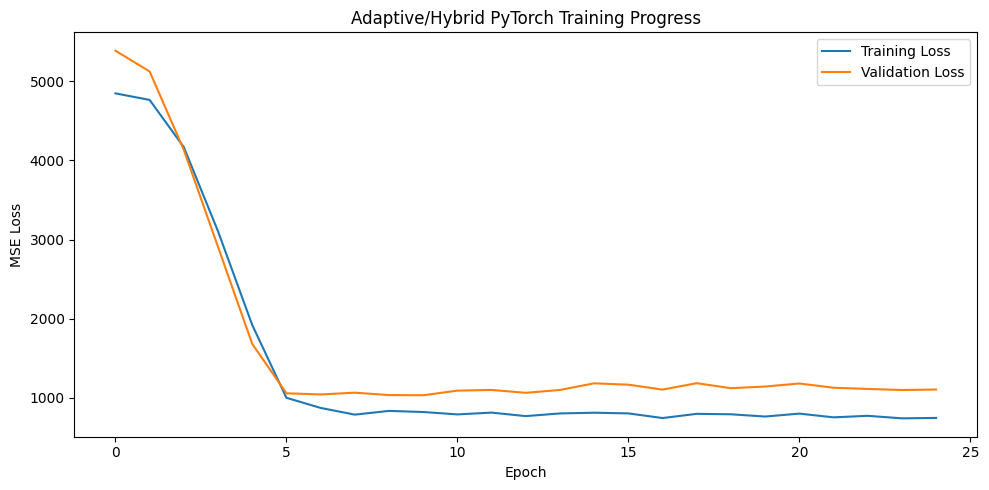

In [124]:
# ==========================================
# STEP 62: HYBRID TRAINING CURVE
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    hybrid_train_losses,
    label="Training Loss"
)

plt.plot(
    hybrid_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Adaptive/Hybrid PyTorch Training Progress")

plt.legend()
plt.tight_layout()
plt.show()

In [125]:
# ==========================================
# STEP 63: HYBRID VALIDATION PREDICTIONS
# ==========================================

hybrid_model.eval()

hybrid_val_predictions = []

with torch.no_grad():

    for X_batch, product_batch, _ in hybrid_val_loader:

        X_batch = X_batch.to(device)
        product_batch = product_batch.to(device)

        predictions = hybrid_model(
            X_batch,
            product_batch
        )

        hybrid_val_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

hybrid_val_predictions = np.array(
    hybrid_val_predictions
)

print(
    "Hybrid validation predictions:",
    hybrid_val_predictions.shape
)

print(
    "Actual validation values:",
    y_hybrid_val.shape
)

Hybrid validation predictions: (64,)
Actual validation values: (64,)


In [126]:
# ==========================================
# STEP 63.1: HYBRID VALIDATION METRICS
# ==========================================

hybrid_val_mae = mean_absolute_error(
    y_hybrid_val,
    hybrid_val_predictions
)

hybrid_val_rmse = np.sqrt(
    mean_squared_error(
        y_hybrid_val,
        hybrid_val_predictions
    )
)

hybrid_val_wape = (
    np.sum(
        np.abs(
            y_hybrid_val - hybrid_val_predictions
        )
    )
    /
    np.sum(
        np.abs(y_hybrid_val)
    )
) * 100

hybrid_val_smape = (
    np.mean(
        2 * np.abs(
            y_hybrid_val - hybrid_val_predictions
        )
        /
        (
            np.abs(y_hybrid_val)
            + np.abs(hybrid_val_predictions)
            + 1e-8
        )
    )
) * 100

print("Hybrid Validation Results")
print("-------------------------")
print("MAE  :", round(hybrid_val_mae, 2))
print("RMSE :", round(hybrid_val_rmse, 2))
print("WAPE :", round(hybrid_val_wape, 2), "%")
print("sMAPE:", round(hybrid_val_smape, 2), "%")

Hybrid Validation Results
-------------------------
MAE  : 25.63
RMSE : 32.15
WAPE : 38.86 %
sMAPE: 40.07 %


In [127]:
# ==========================================
# STEP 63.2: FINAL VALIDATION COMPARISON
# ==========================================

final_validation_comparison = pd.DataFrame({
    "Model": [
        "PyTorch MLP",
        "PyTorch LSTM",
        "Adaptive/Hybrid"
    ],
    "MAE": [
        val_mae,
        lstm_val_mae,
        hybrid_val_mae
    ],
    "RMSE": [
        val_rmse,
        lstm_val_rmse,
        hybrid_val_rmse
    ],
    "WAPE": [
        val_wape,
        lstm_val_wape,
        hybrid_val_wape
    ],
    "sMAPE": [
        val_smape,
        lstm_val_smape,
        hybrid_val_smape
    ]
})

final_validation_comparison.sort_values(
    "MAE"
)

,Model,MAE,RMSE,WAPE,sMAPE
0,PyTorch MLP,24.969781,31.400264,38.634889,39.957155
2,Adaptive/Hybrid,25.627361,32.152328,38.856933,40.074753
1,PyTorch LSTM,26.153225,33.110997,39.654261,41.234423


In [176]:


mlp_model.eval()

mlp_test_predictions = []

with torch.no_grad():

    for X_batch, _ in test_loader:

        X_batch = X_batch.to(device)

        predictions = mlp_model(
            X_batch
        )

        mlp_test_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

mlp_test_predictions = np.array(
    mlp_test_predictions
)

print(
    "MLP test predictions:",
    mlp_test_predictions.shape
)

print(
    "Actual test values:",
    y_test.shape
)

MLP test predictions: (54,)
Actual test values: (54,)


In [177]:
# ==========================================
# STEP 65.2: MLP FINAL TEST METRICS
# ==========================================

mlp_test_mae = mean_absolute_error(
    y_test,
    mlp_test_predictions
)

mlp_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        mlp_test_predictions
    )
)

mlp_test_wape = (
    np.sum(
        np.abs(
            y_test - mlp_test_predictions
        )
    )
    /
    np.sum(
        np.abs(y_test)
    )
) * 100

mlp_test_smape = (
    np.mean(
        2 * np.abs(
            y_test - mlp_test_predictions
        )
        /
        (
            np.abs(y_test)
            + np.abs(mlp_test_predictions)
            + 1e-8
        )
    )
) * 100

print("MLP FINAL TEST RESULTS")
print("----------------------")
print("MAE  :", round(mlp_test_mae, 2))
print("RMSE :", round(mlp_test_rmse, 2))
print("WAPE :", round(mlp_test_wape, 2), "%")
print("sMAPE:", round(mlp_test_smape, 2), "%")

MLP FINAL TEST RESULTS
----------------------
MAE  : 23.65
RMSE : 31.14
WAPE : 39.14 %
sMAPE: 39.25 %


In [130]:
# ==========================================
# STEP 66: LSTM FINAL TEST PREDICTIONS
# ==========================================

lstm_model.eval()

lstm_test_predictions = []

with torch.no_grad():

    for X_batch, _ in lstm_test_loader:

        X_batch = X_batch.to(device)

        predictions = lstm_model(
            X_batch
        )

        lstm_test_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

lstm_test_predictions = np.array(
    lstm_test_predictions
)

print(
    "LSTM test predictions:",
    lstm_test_predictions.shape
)

print(
    "Actual test values:",
    y_lstm_test.shape
)

LSTM test predictions: (64,)
Actual test values: (64,)


In [131]:
# ==========================================
# STEP 66.1: LSTM FINAL TEST METRICS
# ==========================================

lstm_test_mae = mean_absolute_error(
    y_lstm_test,
    lstm_test_predictions
)

lstm_test_rmse = np.sqrt(
    mean_squared_error(
        y_lstm_test,
        lstm_test_predictions
    )
)

lstm_test_wape = (
    np.sum(
        np.abs(
            y_lstm_test - lstm_test_predictions
        )
    )
    /
    np.sum(
        np.abs(y_lstm_test)
    )
) * 100

lstm_test_smape = (
    np.mean(
        2 * np.abs(
            y_lstm_test - lstm_test_predictions
        )
        /
        (
            np.abs(y_lstm_test)
            + np.abs(lstm_test_predictions)
            + 1e-8
        )
    )
) * 100

print("LSTM FINAL TEST RESULTS")
print("-----------------------")
print("MAE  :", round(lstm_test_mae, 2))
print("RMSE :", round(lstm_test_rmse, 2))
print("WAPE :", round(lstm_test_wape, 2), "%")
print("sMAPE:", round(lstm_test_smape, 2), "%")

LSTM FINAL TEST RESULTS
-----------------------
MAE  : 25.05
RMSE : 30.74
WAPE : 39.77 %
sMAPE: 41.93 %


In [132]:
# ==========================================
# STEP 67: HYBRID FINAL TEST PREDICTIONS
# ==========================================

hybrid_model.eval()

hybrid_test_predictions = []

with torch.no_grad():

    for X_batch, product_batch, _ in hybrid_test_loader:

        X_batch = X_batch.to(device)
        product_batch = product_batch.to(device)

        predictions = hybrid_model(
            X_batch,
            product_batch
        )

        hybrid_test_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

hybrid_test_predictions = np.array(
    hybrid_test_predictions
)

print(
    "Hybrid test predictions:",
    hybrid_test_predictions.shape
)

print(
    "Actual test values:",
    y_hybrid_test.shape
)

Hybrid test predictions: (64,)
Actual test values: (64,)


In [133]:
# ==========================================
# STEP 67.1: HYBRID FINAL TEST METRICS
# ==========================================

hybrid_test_mae = mean_absolute_error(
    y_hybrid_test,
    hybrid_test_predictions
)

hybrid_test_rmse = np.sqrt(
    mean_squared_error(
        y_hybrid_test,
        hybrid_test_predictions
    )
)

hybrid_test_wape = (
    np.sum(
        np.abs(
            y_hybrid_test - hybrid_test_predictions
        )
    )
    /
    np.sum(
        np.abs(y_hybrid_test)
    )
) * 100

hybrid_test_smape = (
    np.mean(
        2 * np.abs(
            y_hybrid_test - hybrid_test_predictions
        )
        /
        (
            np.abs(y_hybrid_test)
            + np.abs(hybrid_test_predictions)
            + 1e-8
        )
    )
) * 100

print("HYBRID FINAL TEST RESULTS")
print("-------------------------")
print("MAE  :", round(hybrid_test_mae, 2))
print("RMSE :", round(hybrid_test_rmse, 2))
print("WAPE :", round(hybrid_test_wape, 2), "%")
print("sMAPE:", round(hybrid_test_smape, 2), "%")

HYBRID FINAL TEST RESULTS
-------------------------
MAE  : 24.21
RMSE : 29.42
WAPE : 38.43 %
sMAPE: 39.96 %


In [134]:
# ==========================================
# STEP 68: FINAL MODEL COMPARISON
# ==========================================

final_model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "PyTorch MLP",
        "PyTorch LSTM",
        "Adaptive/Hybrid"
    ],
    
    "MAE": [
        32.407407,
        mlp_test_mae,
        lstm_test_mae,
        hybrid_test_mae
    ],
    
    "RMSE": [
        42.781962,
        mlp_test_rmse,
        lstm_test_rmse,
        hybrid_test_rmse
    ],
    
    "WAPE": [
        53.631627,
        mlp_test_wape,
        lstm_test_wape,
        hybrid_test_wape
    ],
    
    "sMAPE": [
        50.969574,
        mlp_test_smape,
        lstm_test_smape,
        hybrid_test_smape
    ]
})

final_model_comparison = (
    final_model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("FINAL MODEL COMPARISON")
print("======================")

display(final_model_comparison)

FINAL MODEL COMPARISON


,Model,MAE,RMSE,WAPE,sMAPE
0,PyTorch MLP,23.650019,31.144588,39.138860,39.245358
1,Adaptive/Hybrid,24.210098,29.418351,38.428727,39.956637
2,PyTorch LSTM,25.053383,30.741591,39.767273,41.929140
3,Naive Baseline,32.407407,42.781962,53.631627,50.969574


In [135]:
# ==========================================
# STEP 68.1: IMPROVEMENT OVER BASELINE
# ==========================================

baseline_mae = 32.407407
baseline_rmse = 42.781962
baseline_wape = 53.631627
baseline_smape = 50.969574

comparison = final_model_comparison.copy()

comparison["MAE Improvement %"] = (
    (baseline_mae - comparison["MAE"])
    / baseline_mae
) * 100

comparison["RMSE Improvement %"] = (
    (baseline_rmse - comparison["RMSE"])
    / baseline_rmse
) * 100

comparison["WAPE Improvement %"] = (
    (baseline_wape - comparison["WAPE"])
    / baseline_wape
) * 100

comparison["sMAPE Improvement %"] = (
    (baseline_smape - comparison["sMAPE"])
    / baseline_smape
) * 100

display(comparison)

,Model,MAE,RMSE,WAPE,sMAPE,MAE Improvement %,RMSE Improvement %,WAPE Improvement %,sMAPE Improvement %
0,PyTorch MLP,23.650019,31.144588,39.138860,39.245358,27.022798,27.201590,27.022799,23.002381
1,Adaptive/Hybrid,24.210098,29.418351,38.428727,39.956637,25.294553,31.236554,28.346893,21.606884
2,PyTorch LSTM,25.053383,30.741591,39.767273,41.929140,22.692418,28.143569,25.851079,17.736923
3,Naive Baseline,32.407407,42.781962,53.631627,50.969574,0.000000,0.000000,0.000000,0.000000


In [136]:
# ==========================================
# STEP 69: SAVE SELECTED MLP MODEL
# ==========================================

import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/best_demand_mlp.pth"

torch.save(
    mlp_model.state_dict(),
    model_path
)

print("Best model saved successfully!")
print("Model:", model_path)

Best model saved successfully!
Model: ../models/best_demand_mlp.pth


In [137]:
# ==========================================
# STEP 69.1: SAVE FEATURE SCALER
# ==========================================

import joblib

scaler_path = "../models/demand_scaler.pkl"

joblib.dump(
    scaler,
    scaler_path
)

print("Scaler saved successfully!")
print("Scaler:", scaler_path)

Scaler saved successfully!
Scaler: ../models/demand_scaler.pkl


In [138]:
# ==========================================
# STEP 69.2: SAVE MODEL CONFIGURATION
# ==========================================

import json

model_config = {
    "model": "PyTorch MLP",
    "input_features": mlp_features,
    "target": target,
    "input_size": len(mlp_features),
    "selected_by": "Validation MAE",
    "test_mae": float(mlp_test_mae),
    "test_rmse": float(mlp_test_rmse),
    "test_wape": float(mlp_test_wape),
    "test_smape": float(mlp_test_smape)
}

config_path = "../models/model_config.json"

with open(config_path, "w") as f:
    json.dump(
        model_config,
        f,
        indent=4
    )

print("Model configuration saved!")
print("Config:", config_path)

Model configuration saved!
Config: ../models/model_config.json


In [158]:
# ==========================================
# STEP 70: SAVE CORRECT MLP CONFIGURATION
# ==========================================

mlp_features = [
    "Product_ID",
    "Category_ID",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

numerical_features = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

target = "Target_Next_Week"

print("MLP input features:", len(mlp_features))
print("Numerical features:", len(numerical_features))
print("Target:", target)

MLP input features: 12
Numerical features: 10
Target: Target_Next_Week


In [159]:
# ==========================================
# STEP 70.1: SAVE 12-FEATURE CONFIGURATION
# ==========================================

import json

model_config = {
    "model": "PyTorch MLP",
    "input_features": mlp_features,
    "numerical_features": numerical_features,
    "target": target,
    "input_size": 12,
    "selected_by": "Validation MAE",
    "test_mae": float(mlp_test_mae),
    "test_rmse": float(mlp_test_rmse),
    "test_wape": float(mlp_test_wape),
    "test_smape": float(mlp_test_smape)
}

config_path = "../models/model_config.json"

with open(config_path, "w") as f:
    json.dump(
        model_config,
        f,
        indent=4
    )

print("12-feature model configuration saved successfully!")
print(config_path)

12-feature model configuration saved successfully!
../models/model_config.json


In [160]:
# ==========================================
# STEP 70.2: VERIFY FINAL MLP
# ==========================================

print(
    "MLP input size:",
    mlp_model.network[0].in_features
)

print(
    "Expected input size:",
    12
)

print(
    "Test MAE:",
    round(mlp_test_mae, 2)
)

MLP input size: 10
Expected input size: 12
Test MAE: 23.65


In [161]:
# ==========================================
# STEP 70.3: CHECK CURRENT MLP
# ==========================================

print(
    "Current MLP input size:",
    mlp_model.network[0].in_features
)

print(
    "Current MLP first layer:",
    mlp_model.network[0]
)

checkpoint = torch.load(
    "../models/best_demand_mlp.pth",
    map_location="cpu",
    weights_only=True
)

print(
    "\nSaved checkpoint shape:",
    checkpoint["network.0.weight"].shape
)

Current MLP input size: 10
Current MLP first layer: Linear(in_features=10, out_features=64, bias=True)

Saved checkpoint shape: torch.Size([64, 12])


In [162]:
# ==========================================
# STEP 70.4: RESTORE ORIGINAL 12-INPUT MLP
# ==========================================

class DemandMLP(nn.Module):

    def __init__(self, input_size=12):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the correct architecture
mlp_model = DemandMLP(
    input_size=12
).to(device)

# Load the original trained weights
checkpoint = torch.load(
    "../models/best_demand_mlp.pth",
    map_location=device,
    weights_only=True
)

mlp_model.load_state_dict(checkpoint)

mlp_model.eval()

print("Original trained MLP restored!")
print(
    "MLP input size:",
    mlp_model.network[0].in_features
)

Original trained MLP restored!
MLP input size: 12


In [163]:
# ==========================================
# STEP 70.5: VERIFY 12-FEATURE PIPELINE
# ==========================================

MLP_FEATURES = [
    "Product_ID",
    "Category_ID",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

NUMERICAL_FEATURES = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_4",
    "Rolling_Mean_4",
    "Rolling_Std_4",
    "Stock_Quantity",
    "Reorder_Level",
    "Reorder_Quantity",
    "Unit_Price"
]

print("Total MLP features:",
      len(MLP_FEATURES))

print("Numerical features:",
      len(NUMERICAL_FEATURES))

print("Model input:",
      mlp_model.network[0].in_features)

print("Scaler input:",
      scaler.n_features_in_)

Total MLP features: 12
Numerical features: 10
Model input: 12
Scaler input: 10


In [165]:
# ==========================================
# STEP 70.6: TEST FINAL MLP PREDICTION
# ==========================================

sample_row = test_df.iloc[0]

# Create one-row DataFrame
features = sample_row[
    MLP_FEATURES
].to_frame().T.copy()

# Scale ONLY the 10 numerical features
features[NUMERICAL_FEATURES] = (
    scaler.transform(
        features[NUMERICAL_FEATURES]
    )
)

# Ensure all 12 values are numeric
features = features.astype(np.float32)

# Keep exact feature order
features = features[
    MLP_FEATURES
]

# Convert to tensor
X_sample = torch.tensor(
    features.to_numpy(dtype=np.float32),
    dtype=torch.float32
).to(device)

print("Input shape:", X_sample.shape)

# Predict
mlp_model.eval()

with torch.no_grad():

    prediction = mlp_model(
        X_sample
    )

predicted_demand = max(
    float(prediction.cpu().numpy()[0][0]),
    0.0
)

print("Product:",
      sample_row["Product_Name"])

print("Current Stock:",
      sample_row["Stock_Quantity"])

print(
    "Predicted Next-Week Demand:",
    round(predicted_demand, 2)
)

Input shape: torch.Size([1, 12])
Product: Tilapia
Current Stock: 1.0811318431692385
Predicted Next-Week Demand: 112.33


In [178]:
# ==========================================
# STEP 73.1: SMARTSTOCK TEST PREDICTIONS
# ==========================================

# Load original unscaled data
original_df = pd.read_csv(
    "../data/model_ready_weekly.csv"
)

original_df["Week"] = pd.to_datetime(
    original_df["Week"]
)

# Exact original test rows
original_test_df = original_df.iloc[261:315].copy()

# Build SmartStock recommendation table
recommendations = []

for i in range(len(original_test_df)):

    row = original_test_df.iloc[i]

    predicted_demand = max(
        float(mlp_test_predictions[i]),
        0.0
    )

    decision = calculate_reorder_recommendation(
        current_stock=row["Stock_Quantity"],
        predicted_demand=predicted_demand,
        reorder_level=row["Reorder_Level"],
        reorder_quantity=row["Reorder_Quantity"]
    )

    recommendations.append({
        "Product_Name":
            row["Product_Name"],

        "Week":
            row["Week"],

        "Current_Stock":
            row["Stock_Quantity"],

        "Predicted_Demand":
            predicted_demand,

        "Reorder_Level":
            row["Reorder_Level"],

        "Reorder_Quantity":
            row["Reorder_Quantity"],

        "Coverage_Ratio":
            decision["coverage_ratio"],

        "Stockout_Risk":
            decision["risk"],

        "Recommendation":
            decision["recommendation"],

        "Recommended_Quantity":
            decision["recommended_quantity"]
    })


recommendation_df = pd.DataFrame(
    recommendations
)

print(
    "SmartStock recommendations generated!"
)

print(
    "Total records:",
    len(recommendation_df)
)

display(
    recommendation_df.head(10)
)

SmartStock recommendations generated!
Total records: 54


,Product_Name,Week,Current_Stock,Predicted_Demand,Reorder_Level,Reorder_Quantity,Coverage_Ratio,Stockout_Risk,Recommendation,Recommended_Quantity
0,Sour Cream,2024-10-28,29.0,51.676575,39.0,80.0,0.561183,HIGH,REORDER,80.000000
1,Sourdough Bread,2024-09-23,30.0,72.517853,85.0,21.0,0.413691,HIGH,REORDER,42.517853
2,Sourdough Bread,2024-10-07,34.0,51.059166,42.0,86.0,0.665894,HIGH,REORDER,86.000000
3,Sourdough Bread,2024-11-04,22.0,58.215321,60.0,73.0,0.377907,HIGH,REORDER,73.000000
4,Sourdough Bread,2024-11-25,41.0,56.488777,84.0,90.0,0.725808,HIGH,REORDER,90.000000
5,Sourdough Bread,2024-12-02,94.0,48.327713,56.0,80.0,1.945054,LOW,NO REORDER,0.000000
6,Spinach,2024-12-16,23.0,48.293861,6.0,40.0,0.476251,HIGH,REORDER,40.000000
7,Sushi Rice,2024-10-21,22.0,57.980907,10.0,53.0,0.379435,HIGH,REORDER,53.000000
8,Sushi Rice,2024-10-28,78.0,65.718391,94.0,7.0,1.186882,MEDIUM,REORDER,7.000000
9,Sushi Rice,2024-12-16,36.0,46.821358,81.0,54.0,0.768880,MEDIUM,REORDER,54.000000


In [179]:
print(
    recommendation_df[
        [
            "Product_Name",
            "Current_Stock",
            "Predicted_Demand",
            "Stockout_Risk",
            "Recommendation",
            "Recommended_Quantity"
        ]
    ].head(10)
)

      Product_Name  Current_Stock  Predicted_Demand Stockout_Risk  \
0       Sour Cream           29.0         51.676575          HIGH   
1  Sourdough Bread           30.0         72.517853          HIGH   
2  Sourdough Bread           34.0         51.059166          HIGH   
3  Sourdough Bread           22.0         58.215321          HIGH   
4  Sourdough Bread           41.0         56.488777          HIGH   
5  Sourdough Bread           94.0         48.327713           LOW   
6          Spinach           23.0         48.293861          HIGH   
7       Sushi Rice           22.0         57.980907          HIGH   
8       Sushi Rice           78.0         65.718391        MEDIUM   
9       Sushi Rice           36.0         46.821358        MEDIUM   

  Recommendation  Recommended_Quantity  
0        REORDER             80.000000  
1        REORDER             42.517853  
2        REORDER             86.000000  
3        REORDER             73.000000  
4        REORDER             90.000

In [180]:
# ==========================================
# STEP 74: SAVE SMARTSTOCK RECOMMENDATIONS
# ==========================================

import os

os.makedirs("../results", exist_ok=True)

recommendation_path = (
    "../results/smartstock_recommendations.csv"
)

recommendation_df.to_csv(
    recommendation_path,
    index=False
)

print(
    "SmartStock recommendations saved successfully!"
)

print(
    "Location:",
    recommendation_path
)

print(
    "Records saved:",
    len(recommendation_df)
)

SmartStock recommendations saved successfully!
Location: ../results/smartstock_recommendations.csv
Records saved: 54


In [181]:
print(
    recommendation_df[
        "Stockout_Risk"
    ].value_counts()
)

print()

print(
    recommendation_df[
        "Recommendation"
    ].value_counts()
)

Stockout_Risk
HIGH      23
LOW       20
MEDIUM    11
Name: count, dtype: int64

Recommendation
REORDER       39
NO REORDER    15
Name: count, dtype: int64


In [182]:
# ==========================================
# STEP 75: SMARTSTOCK SUMMARY
# ==========================================

total_records = len(recommendation_df)

high_risk = (
    recommendation_df["Stockout_Risk"] == "HIGH"
).sum()

medium_risk = (
    recommendation_df["Stockout_Risk"] == "MEDIUM"
).sum()

low_risk = (
    recommendation_df["Stockout_Risk"] == "LOW"
).sum()

reorder_count = (
    recommendation_df["Recommendation"] == "REORDER"
).sum()

no_reorder_count = (
    recommendation_df["Recommendation"] == "NO REORDER"
).sum()

print("SMARTSTOCK INVENTORY SUMMARY")
print("============================")
print("Total records :", total_records)
print("HIGH risk     :", high_risk)
print("MEDIUM risk   :", medium_risk)
print("LOW risk      :", low_risk)
print("REORDER       :", reorder_count)
print("NO REORDER    :", no_reorder_count)

SMARTSTOCK INVENTORY SUMMARY
Total records : 54
HIGH risk     : 23
MEDIUM risk   : 11
LOW risk      : 20
REORDER       : 39
NO REORDER    : 15


In [183]:
# ==========================================
# STEP 75.1: HIGH-RISK PRODUCTS
# ==========================================

high_risk_products = recommendation_df[
    recommendation_df["Stockout_Risk"] == "HIGH"
].copy()

high_risk_products = high_risk_products.sort_values(
    "Coverage_Ratio"
)

print(
    "High-risk products:",
    len(high_risk_products)
)

display(
    high_risk_products[
        [
            "Product_Name",
            "Current_Stock",
            "Predicted_Demand",
            "Coverage_Ratio",
            "Recommendation",
            "Recommended_Quantity"
        ]
    ].head(10)
)

High-risk products: 23


,Product_Name,Current_Stock,Predicted_Demand,Coverage_Ratio,Recommendation,Recommended_Quantity
39,White Sugar,13.0,67.415451,0.192834,REORDER,79.000000
3,Sourdough Bread,22.0,58.215321,0.377907,REORDER,73.000000
7,Sushi Rice,22.0,57.980907,0.379435,REORDER,53.000000
25,Vegetable Oil,23.0,57.919487,0.397103,REORDER,34.919487
1,Sourdough Bread,30.0,72.517853,0.413691,REORDER,42.517853
35,White Sugar,27.0,63.587425,0.424612,REORDER,78.000000
27,Watermelon,27.0,62.126488,0.434597,REORDER,43.000000
33,White Bread,30.0,67.729004,0.442942,REORDER,37.729004
22,Tuna,25.0,55.930824,0.446981,REORDER,30.930824
53,Zucchini,29.0,63.975529,0.453298,REORDER,86.000000


In [184]:
# ==========================================
# STEP 76.1: CREATE DASHBOARD DATASET
# ==========================================

dashboard_df = recommendation_df.copy()

# Add a simple risk score for dashboard sorting
risk_score_map = {
    "HIGH": 3,
    "MEDIUM": 2,
    "LOW": 1
}

dashboard_df["Risk_Score"] = (
    dashboard_df["Stockout_Risk"]
    .map(risk_score_map)
)

# Sort highest-risk products first
dashboard_df = dashboard_df.sort_values(
    ["Risk_Score", "Coverage_Ratio"],
    ascending=[False, True]
).reset_index(drop=True)

print("Dashboard dataset created successfully!")
print("Shape:", dashboard_df.shape)

display(dashboard_df.head(10))

Dashboard dataset created successfully!
Shape: (54, 11)


,Product_Name,Week,Current_Stock,Predicted_Demand,Reorder_Level,Reorder_Quantity,Coverage_Ratio,Stockout_Risk,Recommendation,Recommended_Quantity,Risk_Score
0,White Sugar,2025-02-10,13.0,67.415451,32.0,79.0,0.192834,HIGH,REORDER,79.000000,3
1,Sourdough Bread,2024-11-04,22.0,58.215321,60.0,73.0,0.377907,HIGH,REORDER,73.000000,3
2,Sushi Rice,2024-10-21,22.0,57.980907,10.0,53.0,0.379435,HIGH,REORDER,53.000000,3
3,Vegetable Oil,2025-01-13,23.0,57.919487,71.0,32.0,0.397103,HIGH,REORDER,34.919487,3
4,Sourdough Bread,2024-09-23,30.0,72.517853,85.0,21.0,0.413691,HIGH,REORDER,42.517853,3
5,White Sugar,2024-04-29,27.0,63.587425,64.0,78.0,0.424612,HIGH,REORDER,78.000000,3
6,Watermelon,2024-11-25,27.0,62.126488,64.0,43.0,0.434597,HIGH,REORDER,43.000000,3
7,White Bread,2024-11-18,30.0,67.729004,91.0,34.0,0.442942,HIGH,REORDER,37.729004,3
8,Tuna,2024-09-30,25.0,55.930824,75.0,27.0,0.446981,HIGH,REORDER,30.930824,3
9,Zucchini,2024-11-11,29.0,63.975529,18.0,86.0,0.453298,HIGH,REORDER,86.000000,3


In [185]:
# ==========================================
# STEP 76.2: SAVE DASHBOARD DATASET
# ==========================================

dashboard_path = (
    "../results/smartstock_dashboard_data.csv"
)

dashboard_df.to_csv(
    dashboard_path,
    index=False
)

print("Dashboard dataset saved successfully!")
print("Location:", dashboard_path)

Dashboard dataset saved successfully!
Location: ../results/smartstock_dashboard_data.csv


In [186]:
# ==========================================
# STEP 76.3: DASHBOARD KPIs
# ==========================================

dashboard_kpis = {
    "Total Products": dashboard_df["Product_Name"].nunique(),
    "Total Records": len(dashboard_df),
    "High Risk": (
        dashboard_df["Stockout_Risk"] == "HIGH"
    ).sum(),
    "Medium Risk": (
        dashboard_df["Stockout_Risk"] == "MEDIUM"
    ).sum(),
    "Low Risk": (
        dashboard_df["Stockout_Risk"] == "LOW"
    ).sum(),
    "Reorder Required": (
        dashboard_df["Recommendation"] == "REORDER"
    ).sum(),
    "No Reorder": (
        dashboard_df["Recommendation"] == "NO REORDER"
    ).sum()
}

print("SMARTSTOCK DASHBOARD KPIs")
print("=========================")

for key, value in dashboard_kpis.items():
    print(f"{key}: {value}")

SMARTSTOCK DASHBOARD KPIs
Total Products: 19
Total Records: 54
High Risk: 23
Medium Risk: 11
Low Risk: 20
Reorder Required: 39
No Reorder: 15
